# Demand Forecasting and Sales Prediction

## 1. Project Overview

This project analyzes historical retail sales data to identify sales patterns,
understand store and product performance, and develop machine learning models
for demand forecasting.

## Objectives
- Analyze historical sales trends.
- Understand store-level and item-level sales patterns.
- Perform exploratory data analysis.
- Create time-based features.
- Build and evaluate demand forecasting models.
- Forecast future sales.
- Develop a sales prediction application.

## 2. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error

## 3. Load Dataset
Load the historical retail sales dataset for analysis.

In [2]:
df = pd.read_csv("../data/raw/store_sales.csv")
df.head()

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10



## 4. Data Understanding

In this section, we examine the dataset structure, dimensions, data types, and statistical properties to understand the historical retail sales data.


In [3]:
df.shape

(913000, 4)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   date    913000 non-null  str  
 1   store   913000 non-null  int64
 2   item    913000 non-null  int64
 3   sales   913000 non-null  int64
dtypes: int64(3), str(1)
memory usage: 36.6 MB


In [5]:
df.describe()

,store,item,sales
count,913000.000000,913000.000000,913000.000000
mean,5.500000,25.500000,52.250287
std,2.872283,14.430878,28.801144
min,1.000000,1.000000,0.000000
25%,3.000000,13.000000,30.000000
50%,5.500000,25.500000,47.000000
75%,8.000000,38.000000,70.000000
max,10.000000,50.000000,231.000000


In [6]:
df.columns

Index(['date', 'store', 'item', 'sales'], dtype='str')


## 5. Data Cleaning and Preprocessing

In this section, we verify data quality and convert columns into appropriate data types for time-series analysis.


In [7]:
df["date"] = pd.to_datetime(df["date"])

In [8]:
df.dtypes

date     datetime64[us]
store             int64
item              int64
sales             int64
dtype: object

In [9]:
df.isnull().sum()

date     0
store    0
item     0
sales    0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df["date"].min(), df["date"].max()

(Timestamp('2013-01-01 00:00:00'), Timestamp('2017-12-31 00:00:00'))

In [12]:
(df["sales"] < 0).sum()

np.int64(0)


## 6. Exploratory Data Analysis (EDA)

In this section, we analyze sales patterns across dates, stores, and products to understand historical demand and identify important business trends.


In [13]:
df["sales"].agg(["sum", "mean", "median", "min", "max"])

sum       4.770451e+07
mean      5.225029e+01
median    4.700000e+01
min       0.000000e+00
max       2.310000e+02
Name: sales, dtype: float64

### Store-Wise Sales Distribution

In [14]:
store_sales = df.groupby("store")["sales"].sum().sort_values(ascending=False)

store_sales

store
2     6120128
8     5856169
3     5435144
10    5360158
9     5025976
4     5012639
1     4315603
5     3631016
6     3627670
7     3320009
Name: sales, dtype: int64

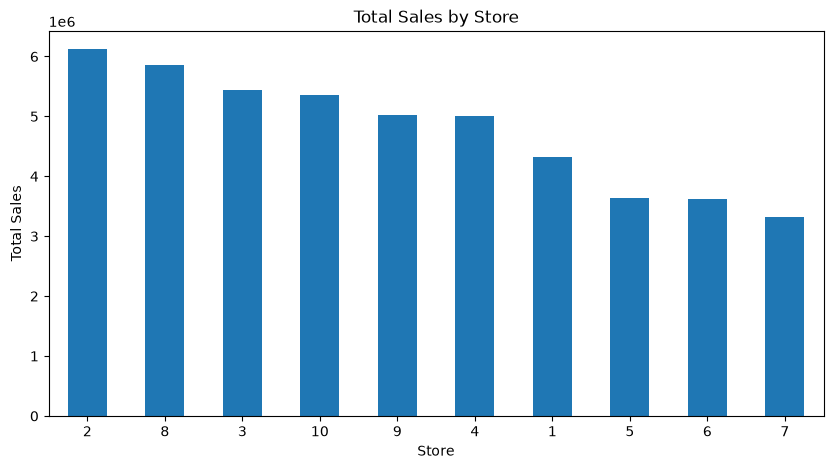

In [15]:
plt.figure(figsize=(10, 5))

store_sales.plot(kind="bar")

plt.title("Total Sales by Store")
plt.xlabel("Store")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)

plt.savefig("../visualizations/store_sales_distribution.png",
            dpi=300, bbox_inches="tight")

plt.show()

### Item-Wise Sales Distribution

In [16]:
item_sales = df.groupby("item")["sales"].sum().sort_values(ascending=False)

item_sales

item
15    1607442
28    1604713
13    1539621
18    1538876
25    1473334
45    1471467
38    1470330
22    1469971
36    1406548
8     1405108
10    1337133
11    1271925
12    1271534
29    1271240
33    1270183
24    1205975
50    1203009
35    1201541
14    1071531
31    1070845
46    1070764
2     1069564
7     1068777
6     1068281
9      938379
48     937703
43     936635
26     869981
20     867641
32     803107
39     801311
19     736892
30     736554
21     736190
42     669925
3      669087
17     602486
44     536811
49     535663
23     534979
37     534258
40     534094
34     469935
16     468480
27     402628
4      401907
47     401781
41     401759
1      401384
5      335230
Name: sales, dtype: int64

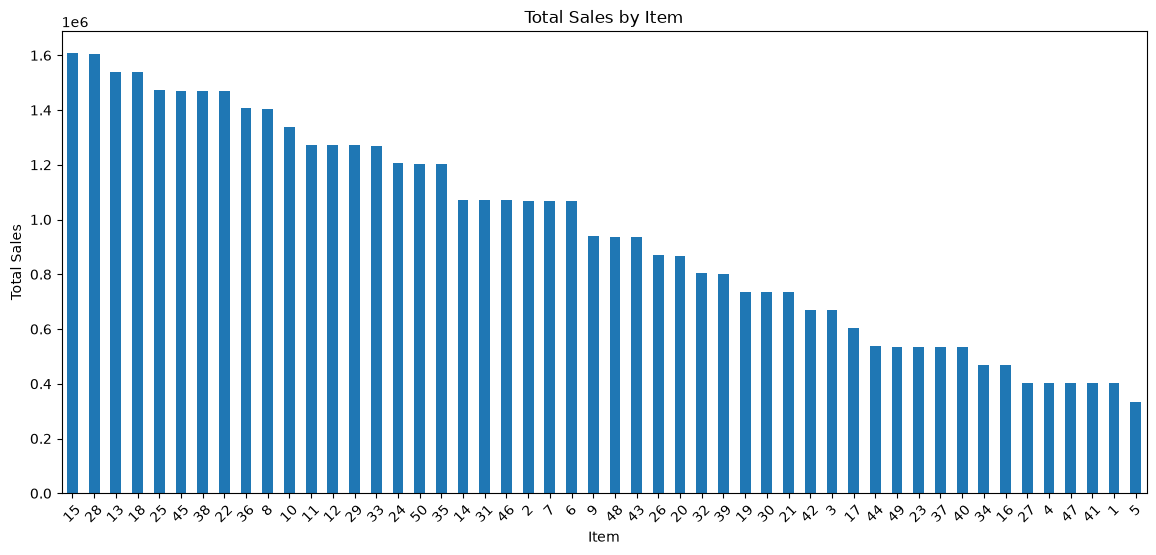

In [17]:
plt.figure(figsize=(14, 6))

item_sales.plot(kind="bar")

plt.title("Total Sales by Item")
plt.xlabel("Item")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.savefig("../visualizations/item_sales_distribution.png",
            dpi=300, bbox_inches="tight")

plt.show()

### Monthly Sales Trend

In [18]:
monthly_sales = df.groupby(
    df["date"].dt.to_period("M")
)["sales"].sum()

monthly_sales.head()

date
2013-01    454904
2013-02    459417
2013-03    617382
2013-04    682274
2013-05    763242
Freq: M, Name: sales, dtype: int64

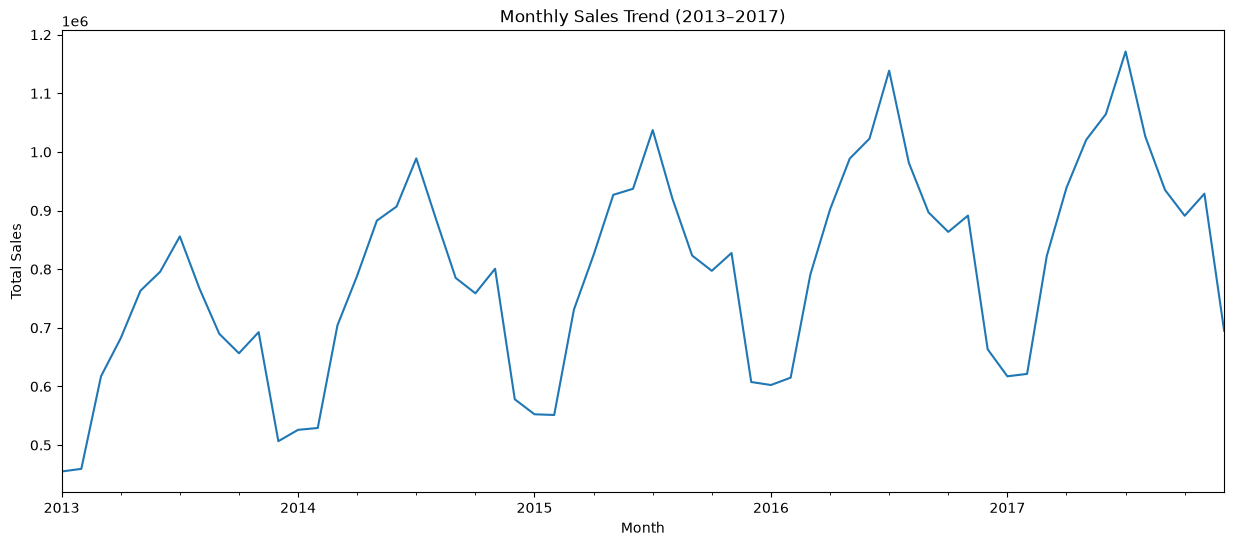

In [19]:
plt.figure(figsize=(15, 6))

monthly_sales.plot()

plt.title("Monthly Sales Trend (2013–2017)")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.savefig("../visualizations/monthly_sales_trend.png",
            dpi=300, bbox_inches="tight")

plt.show()

### Month-of-Year Sales Pattern

In [20]:
monthly_pattern = df.groupby(
    df["date"].dt.month
)["sales"].mean()

monthly_pattern


date
1     35.524503
2     39.378397
3     47.305574
4     55.152893
5     59.128219
6     63.025480
7     66.998619
8     59.105226
9     55.072760
10    51.193806
11    55.218080
12    39.365265
Name: sales, dtype: float64

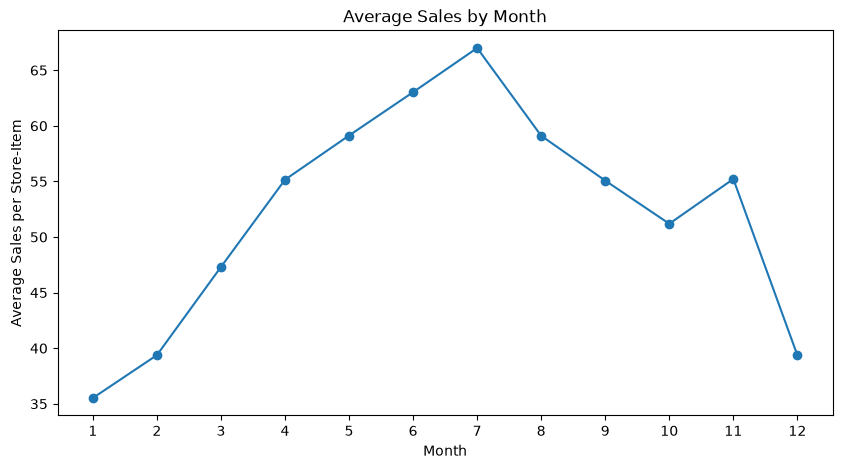

In [21]:
plt.figure(figsize=(10, 5))

monthly_pattern.plot(kind="line", marker="o")

plt.title("Average Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Sales per Store-Item")
plt.xticks(range(1, 13))

plt.savefig("../visualizations/monthly_seasonality.png",
            dpi=300, bbox_inches="tight")

plt.show()

### Daily Sales Trend

In [22]:
daily_sales = df.groupby("date")["sales"].sum()

daily_sales.head()

date
2013-01-01    13696
2013-01-02    13678
2013-01-03    14488
2013-01-04    15677
2013-01-05    16237
Name: sales, dtype: int64

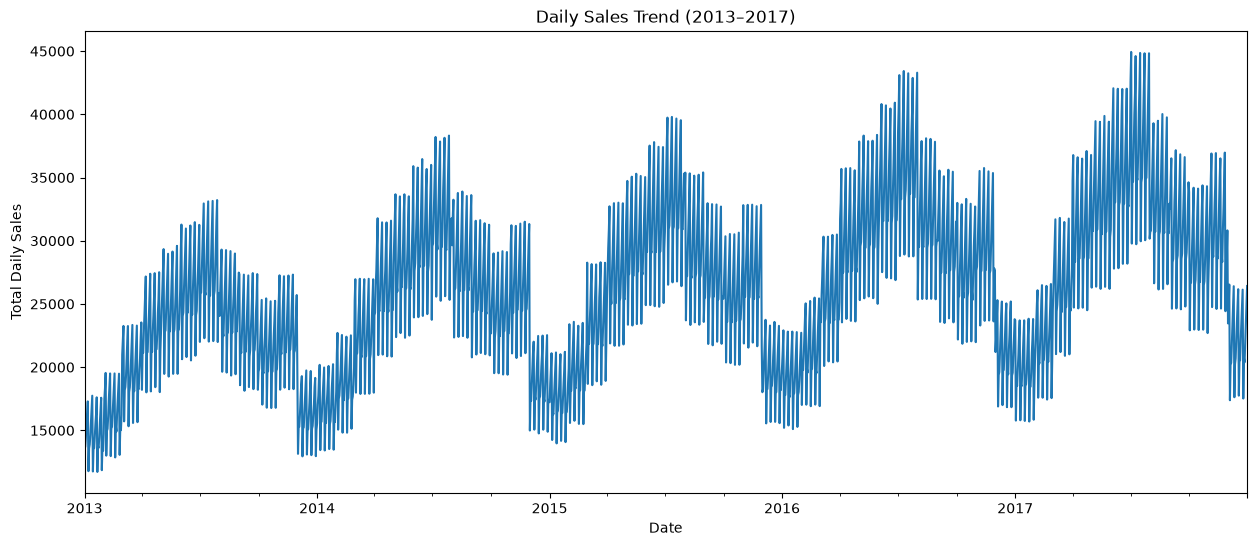

In [23]:
plt.figure(figsize=(15, 6))

daily_sales.plot()

plt.title("Daily Sales Trend (2013–2017)")
plt.xlabel("Date")
plt.ylabel("Total Daily Sales")

plt.savefig("../visualizations/daily_sales_trend.png",
            dpi=300, bbox_inches="tight")

plt.show()

### Day-of-Week Sales Pattern

In [24]:
weekday_sales = df.groupby(
    df["date"].dt.day_of_week
)["sales"].mean()

weekday_sales

date
0    41.429638
1    48.225908
2    48.368506
3    51.723218
4    55.157249
5    58.662697
6    62.143333
Name: sales, dtype: float64

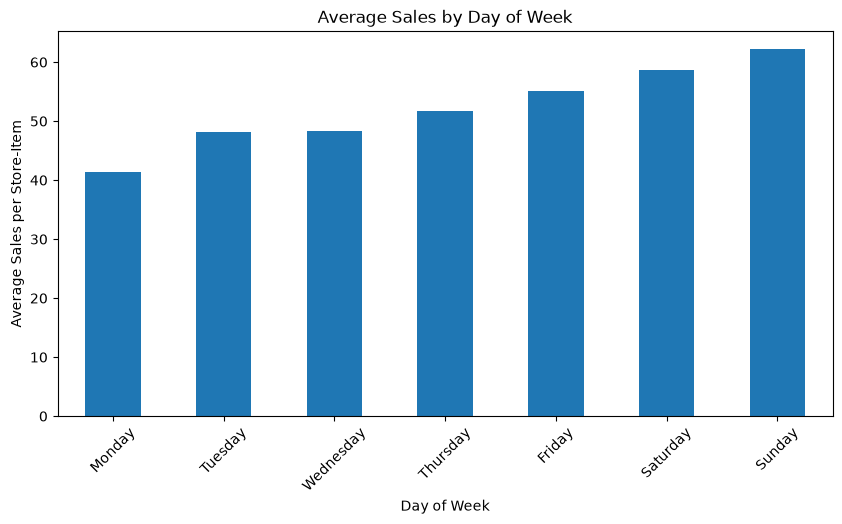

In [25]:
plt.figure(figsize=(10, 5))

weekday_sales.plot(kind="bar")

plt.title("Average Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Sales per Store-Item")
plt.xticks(
    ticks=range(7),
    labels=["Monday", "Tuesday", "Wednesday", "Thursday",
            "Friday", "Saturday", "Sunday"],
    rotation=45
)

plt.savefig("../visualizations/weekday_sales_pattern.png",
            dpi=300, bbox_inches="tight")

plt.show()

### EDA Summary

- Store 2 recorded the highest total sales, while Store 7 recorded the lowest.
- Item 15 and Item 28 were the highest-selling products.
- Monthly sales generally increased from 2013 to 2017.
- July recorded the highest average monthly sales.
- January and December recorded the lowest average monthly sales.
- Sunday had the highest average sales, while Monday had the lowest.
- Daily sales showed recurring weekly fluctuations and an overall upward trend.

## 7. Feature Engineering

Feature engineering is the process of creating meaningful input variables
from existing data to improve machine learning model performance.

In this project, we create time-based features from historical sales dates
to help forecasting models learn yearly, monthly, weekly, and daily patterns.

In [26]:
df_model = df.copy()

In [27]:
df_model["year"] = df_model["date"].dt.year
df_model["month"] = df_model["date"].dt.month
df_model["day"] = df_model["date"].dt.day
df_model["day_of_week"] = df_model["date"].dt.day_of_week
df_model["day_of_year"] = df_model["date"].dt.day_of_year
df_model["week_of_year"] = df_model["date"].dt.isocalendar().week.astype(int)

In [28]:
df_model.head()

,date,store,item,sales,year,month,day,day_of_week,day_of_year,week_of_year
0,2013-01-01,1,1,13,2013,1,1,1,1,1
1,2013-01-02,1,1,11,2013,1,2,2,2,1
2,2013-01-03,1,1,14,2013,1,3,3,3,1
3,2013-01-04,1,1,13,2013,1,4,4,4,1
4,2013-01-05,1,1,10,2013,1,5,5,5,1


In [29]:
df_model = df_model.sort_values(
    ["store", "item", "date"]
).reset_index(drop=True)

In [30]:
df_model.head()

,date,store,item,sales,year,month,day,day_of_week,day_of_year,week_of_year
0,2013-01-01,1,1,13,2013,1,1,1,1,1
1,2013-01-02,1,1,11,2013,1,2,2,2,1
2,2013-01-03,1,1,14,2013,1,3,3,3,1
3,2013-01-04,1,1,13,2013,1,4,4,4,1
4,2013-01-05,1,1,10,2013,1,5,5,5,1


In [31]:
df_model[["date", "store", "item", "sales"]].head()

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


### Lag Features

Lag features represent historical sales values for the same store and item.
They help forecasting models learn from previous demand.

In this project, we create 1-day and 7-day lag features to capture
short-term and weekly sales patterns.

In [32]:
df_model["lag_1"] = df_model.groupby(
    ["store", "item"]
)["sales"].shift(1)

df_model["lag_7"] = df_model.groupby(
    ["store", "item"]
)["sales"].shift(7)

In [33]:
df_model[["date", "store", "item", "sales", "lag_1", "lag_7"]].head(10)

,date,store,item,sales,lag_1,lag_7
0,2013-01-01,1,1,13,NaN,NaN
1,2013-01-02,1,1,11,13.0,NaN
2,2013-01-03,1,1,14,11.0,NaN
3,2013-01-04,1,1,13,14.0,NaN
4,2013-01-05,1,1,10,13.0,NaN
5,2013-01-06,1,1,12,10.0,NaN
6,2013-01-07,1,1,10,12.0,NaN
7,2013-01-08,1,1,9,10.0,13.0
8,2013-01-09,1,1,12,9.0,11.0
9,2013-01-10,1,1,9,12.0,14.0


### Rolling Features

Rolling features summarize historical sales over a fixed time window.
They help forecasting models understand recent demand trends.

In this project, we create 7-day and 30-day rolling averages.
To prevent data leakage, we shift sales by one day before calculating
the rolling averages.

In [34]:
grouped_sales = df_model.groupby(["store", "item"])["sales"]

df_model["rolling_mean_7"] = grouped_sales.transform(
    lambda x: x.shift(1).rolling(window=7).mean()
)

df_model["rolling_mean_30"] = grouped_sales.transform(
    lambda x: x.shift(1).rolling(window=30).mean()
)

In [35]:
df_model[
    ["date", "sales", "lag_1", "lag_7", "rolling_mean_7", "rolling_mean_30"]
].head(35)

,date,sales,lag_1,lag_7,rolling_mean_7,rolling_mean_30
0,2013-01-01,13,NaN,NaN,NaN,NaN
1,2013-01-02,11,13.0,NaN,NaN,NaN
2,2013-01-03,14,11.0,NaN,NaN,NaN
3,2013-01-04,13,14.0,NaN,NaN,NaN
4,2013-01-05,10,13.0,NaN,NaN,NaN
5,2013-01-06,12,10.0,NaN,NaN,NaN
6,2013-01-07,10,12.0,NaN,NaN,NaN
7,2013-01-08,9,10.0,13.0,11.857143,NaN
8,2013-01-09,12,9.0,11.0,11.285714,NaN
9,2013-01-10,9,12.0,14.0,11.428571,NaN


### Additional Lag Features

We create 14-day and 28-day lag features to capture sales patterns
from two weeks and four weeks earlier.
These features provide additional historical information to the forecasting models.

In [36]:
df_model["lag_14"] = df_model.groupby(
    ["store", "item"]
)["sales"].shift(14)

df_model["lag_28"] = df_model.groupby(
    ["store", "item"]
)["sales"].shift(28)

In [37]:
df_model[
    ["date", "sales", "lag_14", "lag_28"]
].head(35)

,date,sales,lag_14,lag_28
0,2013-01-01,13,NaN,NaN
1,2013-01-02,11,NaN,NaN
2,2013-01-03,14,NaN,NaN
3,2013-01-04,13,NaN,NaN
4,2013-01-05,10,NaN,NaN
5,2013-01-06,12,NaN,NaN
6,2013-01-07,10,NaN,NaN
7,2013-01-08,9,NaN,NaN
8,2013-01-09,12,NaN,NaN
9,2013-01-10,9,NaN,NaN


### Prepare Modeling Dataset

The lag and rolling features introduce missing values at the beginning
of each store-item time series.

We remove rows containing missing feature values so that the dataset
can be used for machine learning model training.
The original dataset remains unchanged.

In [38]:
df_ml = df_model.dropna().copy()

In [39]:
df_ml.shape

(898000, 16)

In [40]:
df_ml.isnull().sum()

date               0
store              0
item               0
sales              0
year               0
month              0
day                0
day_of_week        0
day_of_year        0
week_of_year       0
lag_1              0
lag_7              0
rolling_mean_7     0
rolling_mean_30    0
lag_14             0
lag_28             0
dtype: int64

In [41]:
df_ml.head()

,date,store,item,sales,year,month,day,day_of_week,day_of_year,week_of_year,lag_1,lag_7,rolling_mean_7,rolling_mean_30,lag_14,lag_28
30,2013-01-31,1,1,13,2013,1,31,3,31,5,9.0,8.0,10.285714,10.500000,16.0,14.0
31,2013-02-01,1,1,11,2013,2,1,4,32,5,13.0,14.0,11.000000,10.500000,7.0,13.0
32,2013-02-02,1,1,21,2013,2,2,5,33,5,11.0,12.0,10.571429,10.500000,18.0,10.0
33,2013-02-03,1,1,15,2013,2,3,6,34,5,21.0,12.0,11.857143,10.733333,15.0,12.0
34,2013-02-04,1,1,14,2013,2,4,0,35,6,15.0,11.0,12.285714,10.800000,8.0,10.0


## 8. Train-Test Split

For time-series forecasting, data must be split chronologically
rather than randomly.

We use historical data for training and the most recent period
for testing to evaluate forecasting performance on unseen dates.

In [42]:
df_ml["date"].min(), df_ml["date"].max()

(Timestamp('2013-01-31 00:00:00'), Timestamp('2017-12-31 00:00:00'))

### Chronological Train-Test Split

We use data from 2013 through 2016 for training
and data from 2017 for testing.

This chronological split ensures that the model is evaluated
on future dates that it has not seen during training.

In [43]:
train = df_ml[df_ml["date"] < "2017-01-01"].copy()

test = df_ml[df_ml["date"] >= "2017-01-01"].copy()

In [44]:
train.shape, test.shape

((715500, 16), (182500, 16))

In [45]:
train["date"].min(), train["date"].max()

(Timestamp('2013-01-31 00:00:00'), Timestamp('2016-12-31 00:00:00'))

In [46]:
test["date"].min(), test["date"].max()

(Timestamp('2017-01-01 00:00:00'), Timestamp('2017-12-31 00:00:00'))

## 9. Feature Selection

Feature selection identifies the input variables used by machine learning models
to predict the target variable.

In this project, we use store, item, time-based features, lag features,
and rolling averages to predict daily sales.

The target variable is sales. We exclude the actual sales column from
the input features to prevent target leakage.

### Selecting Input Features and Target

In [47]:
features = [
    "store",
    "item",
    "year",
    "month",
    "day",
    "day_of_week",
    "day_of_year",
    "week_of_year",
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_30"
]

X_train = train[features]
y_train = train["sales"]

X_test = test[features]
y_test = test["sales"]

In [48]:
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((715500, 14), (715500,), (182500, 14), (182500,))

### 10.Seasonal Naive Forecast

The seasonal naive forecasting method predicts sales using
the sales value from seven days earlier.

This approach captures weekly sales patterns and provides
a baseline against which machine learning models can be evaluated.

In [49]:
y_pred_baseline = X_test["lag_7"]

baseline_mae = mean_absolute_error(y_test, y_pred_baseline)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_baseline)
)

nonzero_mask = y_test != 0

baseline_mape = np.mean(
    np.abs(
        (y_test[nonzero_mask] - y_pred_baseline[nonzero_mask])
        / y_test[nonzero_mask]
    )
) * 100

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)
print("Baseline MAPE:", baseline_mape)

Baseline MAE: 8.841452054794521
Baseline RMSE: 11.596704066478521
Baseline MAPE: 17.935501181730384



### Seasonal Naive Baseline – Actual vs Predicted Sales

This visualization compares actual sales with Seasonal Naive Baseline predictions
for the 2017 test dataset.

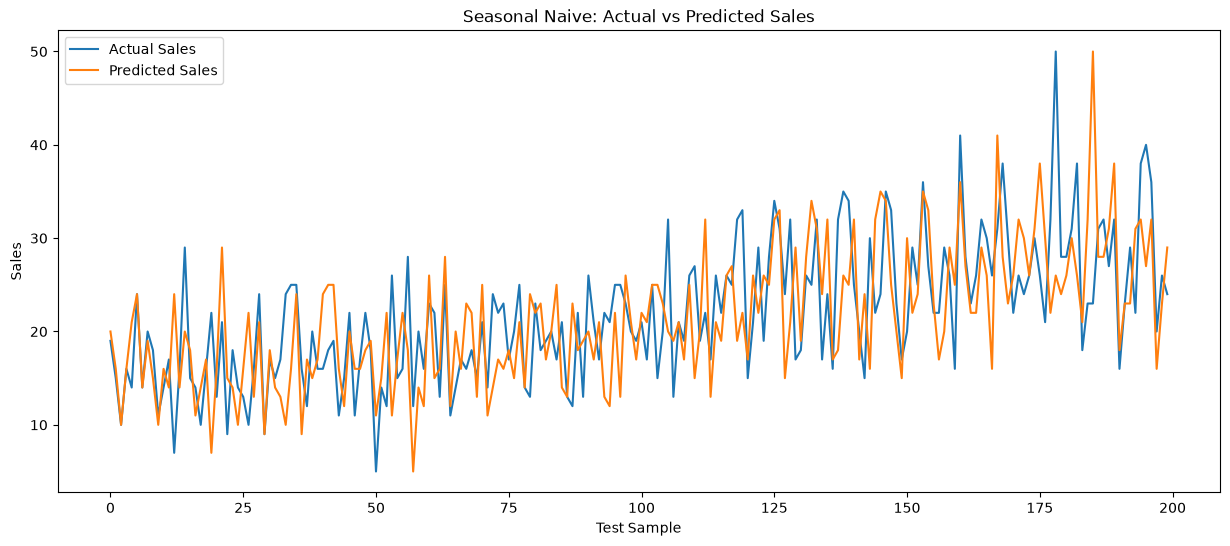

In [50]:
plt.figure(figsize=(15, 6))

plt.plot(y_test.iloc[:200].values, label="Actual Sales")
plt.plot(y_pred_baseline.iloc[:200].values, label="Predicted Sales")

plt.title("Seasonal Naive: Actual vs Predicted Sales")
plt.xlabel("Test Sample")
plt.ylabel("Sales")
plt.legend()

plt.savefig("../visualizations/seasonal_naive_actual_vs_predicted.png",
            dpi=300, bbox_inches="tight")
plt.show()

## 11. Random Forest Regression

Random Forest is an ensemble machine learning algorithm that combines multiple decision trees to make predictions.

In this project, Random Forest is used to predict daily store sales using historical sales data, store and item information, time-based features, lag features, and rolling averages.

The model is trained on sales data from 2013 to 2016 and evaluated on the unseen 2017 dataset.

In [51]:
from sklearn.ensemble import RandomForestRegressor

### Training the Random Forest Model

The Random Forest model is trained using historical sales data
from 2013 through 2016.

The trained model learns relationships between the selected
features and daily sales values.

In [52]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [53]:
rf_model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [54]:
y_pred_rf = rf_model.predict(X_test)

In [55]:
y_pred_rf.shape

(182500,)

In [56]:
rf_mae = mean_absolute_error(y_test, y_pred_rf)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

nonzero_mask = y_test != 0

rf_mape = np.mean(
    np.abs(
        (y_test[nonzero_mask] - y_pred_rf[nonzero_mask])
        / y_test[nonzero_mask]
    )
) * 100

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)
print("Random Forest MAPE:", rf_mape)

Random Forest MAE: 6.2730021813259995
Random Forest RMSE: 8.156662273879752
Random Forest MAPE: 12.934868191254647


### Random Forest – Actual vs Predicted Sales

This visualization compares actual sales with Random Forest predictions
for the 2017 test dataset.

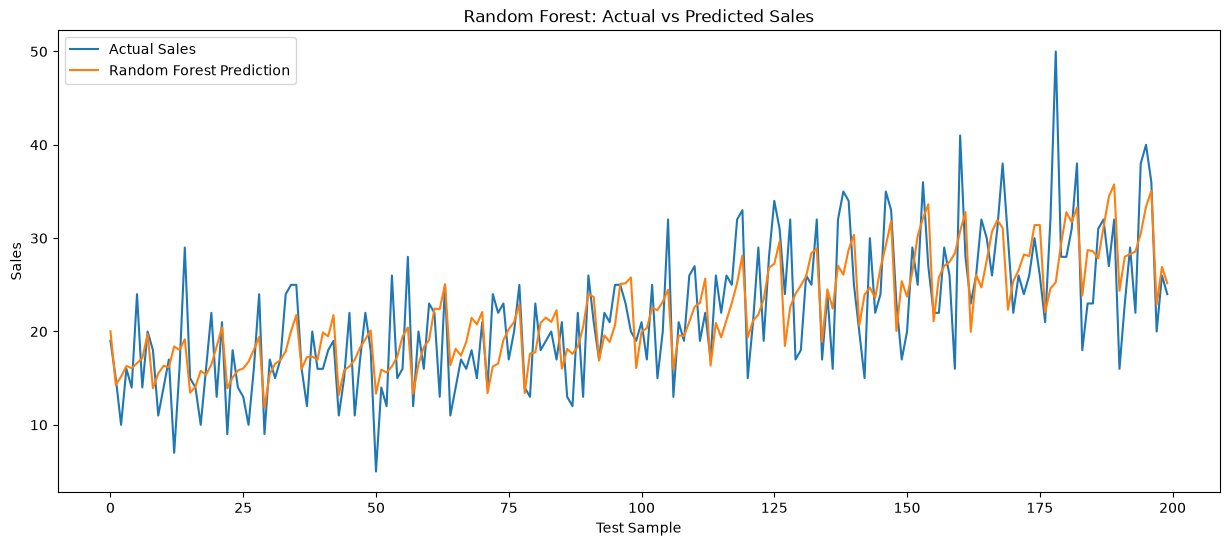

In [57]:
plt.figure(figsize=(15, 6))

plt.plot(y_test.iloc[:200].values, label="Actual Sales")
plt.plot(y_pred_rf[:200], label="Random Forest Prediction")

plt.title("Random Forest: Actual vs Predicted Sales")
plt.xlabel("Test Sample")
plt.ylabel("Sales")
plt.legend()

plt.savefig("../visualizations/random_forest_actual_vs_predicted.png",
            dpi=300, bbox_inches="tight")
plt.show()

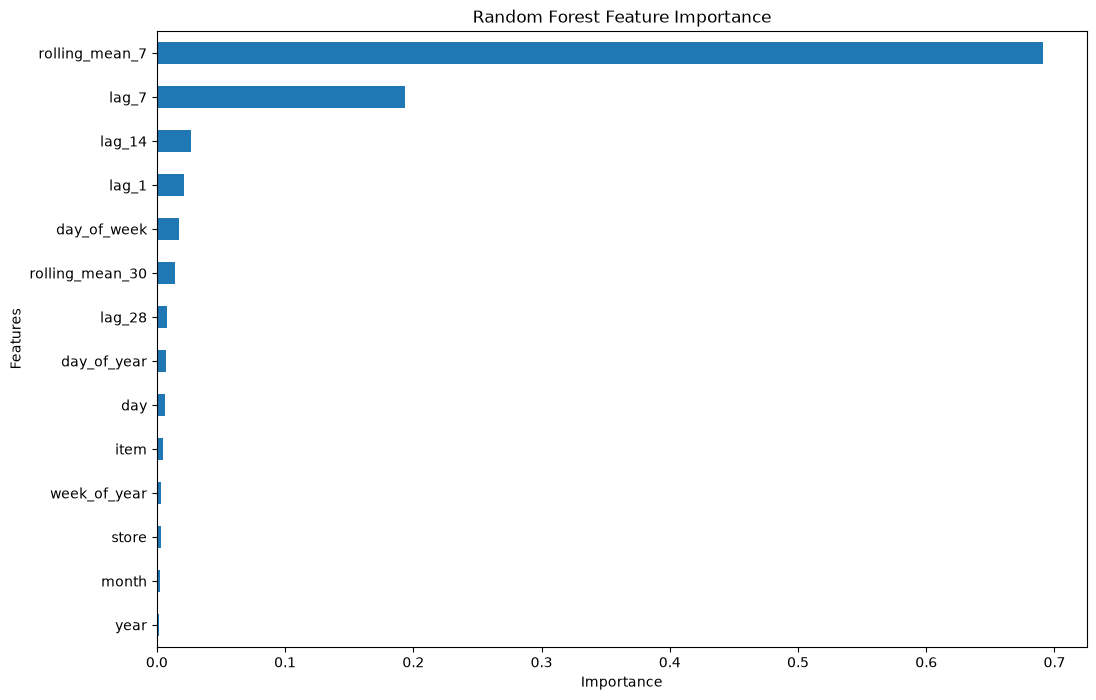

In [58]:
rf_importance = pd.Series(
    rf_model.feature_importances_,
    index=features
).sort_values(ascending=False)

plt.figure(figsize=(12, 8))

rf_importance.plot(kind="barh")

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.gca().invert_yaxis()

plt.savefig("../visualizations/random_forest_feature_importance.png",
            dpi=300, bbox_inches="tight")
plt.show()

### Random Forest Evaluation Conclusion

The Random Forest model achieved an MAE of 6.2730, an RMSE of 8.1567, and a MAPE of 12.9349% on the test dataset.

These metrics indicate the model's prediction error and percentage-based forecasting performance on unseen sales data.

The model's performance will be compared with other forecasting approaches in the model comparison section.

## 12. XGBoost Regression

XGBoost (Extreme Gradient Boosting) is an ensemble machine learning algorithm that builds decision trees sequentially to improve prediction accuracy.

In this project, XGBoost uses historical sales data and engineered features to predict daily sales for individual stores and items.

The model is trained using data from 2013 to 2016 and evaluated on the unseen 2017 dataset.

XGBoost performance is evaluated using MAE, RMSE, and MAPE.

In [59]:
from xgboost import XGBRegressor

In [60]:
xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

In [61]:
xgb_model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [62]:
y_pred_xgb = xgb_model.predict(X_test)

In [63]:
y_pred_xgb.shape

(182500,)

In [64]:
xgb_mae = mean_absolute_error(y_test, y_pred_xgb)

xgb_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_xgb)
)

nonzero_mask = y_test != 0

xgb_mape = np.mean(
    np.abs(
        (y_test[nonzero_mask] - y_pred_xgb[nonzero_mask])
        / y_test[nonzero_mask]
    )
) * 100

print("XGBoost MAE:", xgb_mae)
print("XGBoost RMSE:", xgb_rmse)
print("XGBoost MAPE:", xgb_mape)

XGBoost MAE: 6.101734161376953
XGBoost RMSE: 7.929729833630841
XGBoost MAPE: 12.587755245100308


### XGBoost – Actual vs Predicted Sales

This visualization compares actual sales with XGBoost predictions
for the 2017 test dataset.

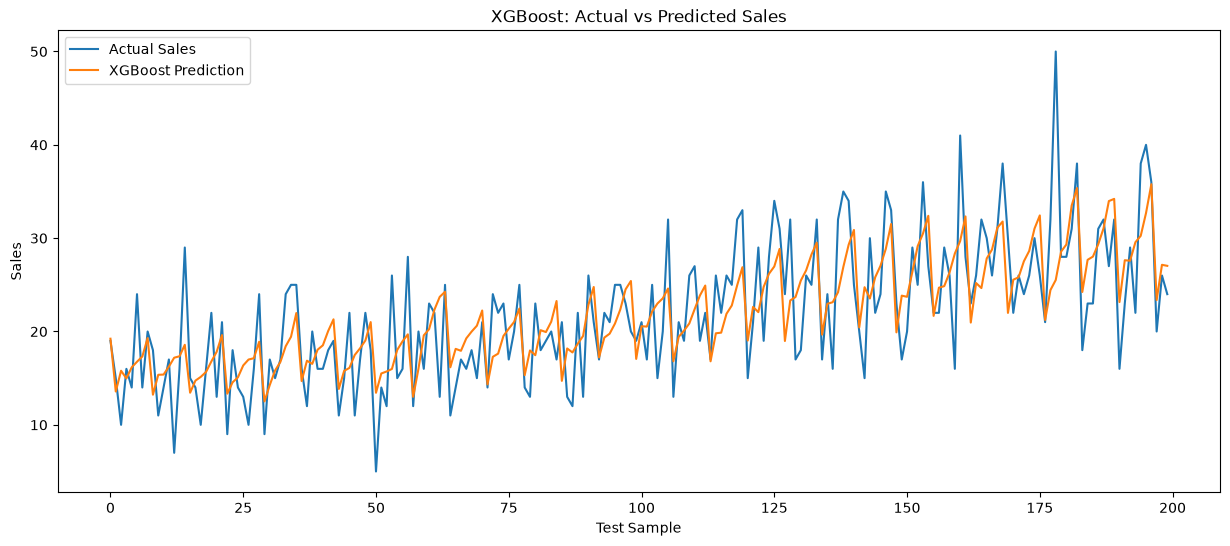

In [65]:
plt.figure(figsize=(15, 6))

plt.plot(y_test.iloc[:200].values, label="Actual Sales")
plt.plot(y_pred_xgb[:200], label="XGBoost Prediction")

plt.title("XGBoost: Actual vs Predicted Sales")
plt.xlabel("Test Sample")
plt.ylabel("Sales")
plt.legend()

plt.savefig("../visualizations/xgboost_actual_vs_predicted.png",
            dpi=300, bbox_inches="tight")
plt.show()

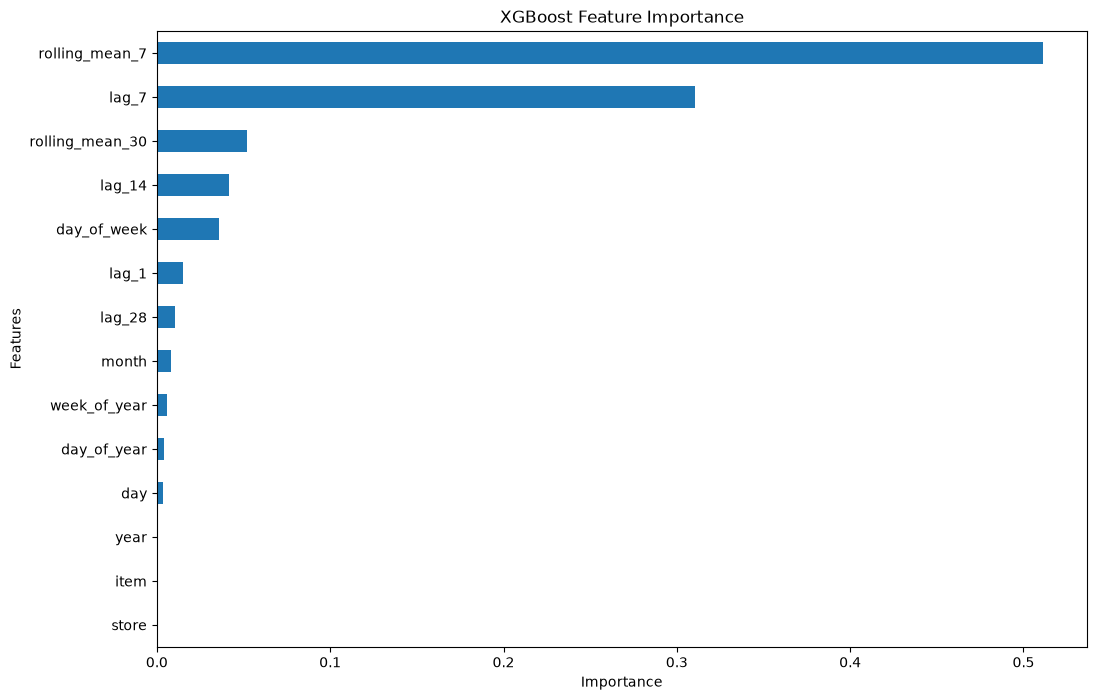

In [66]:
xgb_importance = pd.Series(
    xgb_model.feature_importances_,
    index=features
).sort_values(ascending=False)

plt.figure(figsize=(12, 8))

xgb_importance.plot(kind="barh")

plt.title("XGBoost Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.gca().invert_yaxis()

plt.savefig("../visualizations/xgboost_feature_importance.png",
            dpi=300, bbox_inches="tight")
plt.show()

### XGBoost Evaluation Conclusion

The XGBoost model achieved an MAE of 6.1017, an RMSE of 7.9297, and a MAPE of 12.5878% on the test dataset.

Compared with Random Forest, XGBoost achieved lower prediction errors across all three evaluation metrics.

The results indicate that XGBoost currently provides better forecasting performance among the evaluated machine learning models.

Further forecasting models will be evaluated before selecting the final model.

## 13. SARIMA Forecasting

SARIMA (Seasonal Autoregressive Integrated Moving Average) is a statistical time-series forecasting model that captures autoregressive patterns, trends, and seasonality.

Unlike Random Forest and XGBoost, SARIMA directly models temporal dependencies in historical sales data.

In this project, SARIMA is used to forecast aggregate daily sales across all stores and items, allowing us to evaluate a traditional statistical forecasting approach alongside machine learning models.

The model is evaluated using MAE, RMSE, and MAPE on the 2017 test period.

In [67]:
daily_sales = df.groupby("date")["sales"].sum().reset_index()

daily_sales.head()

,date,sales
0,2013-01-01,13696
1,2013-01-02,13678
2,2013-01-03,14488
3,2013-01-04,15677
4,2013-01-05,16237


In [68]:
daily_sales = daily_sales.set_index("date")

In [69]:
daily_sales = daily_sales.asfreq("D")

In [70]:
sarima_train = daily_sales.loc[
    daily_sales.index < "2017-01-01", "sales"
]

sarima_test = daily_sales.loc[
    daily_sales.index >= "2017-01-01", "sales"
]

In [71]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [72]:
sarima_model = SARIMAX(
    sarima_train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7)
)

In [73]:
sarima_results = sarima_model.fit()

In [74]:
sarima_forecast = sarima_results.forecast(
    steps=len(sarima_test)
)

In [75]:
sarima_forecast.shape

(365,)

In [76]:
sarima_mae = mean_absolute_error(
    sarima_test, sarima_forecast
)

sarima_rmse = np.sqrt(
    mean_squared_error(sarima_test, sarima_forecast)
)

nonzero_mask = sarima_test != 0

sarima_mape = np.mean(
    np.abs(
        (sarima_test[nonzero_mask] - sarima_forecast[nonzero_mask])
        / sarima_test[nonzero_mask]
    )
) * 100

print("SARIMA MAE:", sarima_mae)
print("SARIMA RMSE:", sarima_rmse)
print("SARIMA MAPE:", sarima_mape)

SARIMA MAE: 7593.769048526345
SARIMA RMSE: 8979.641387110474
SARIMA MAPE: 23.615391127124063


### SARIMA – Actual vs Forecast Daily Sales

This visualization compares actual aggregate daily sales
with SARIMA forecasts for the year 2017.

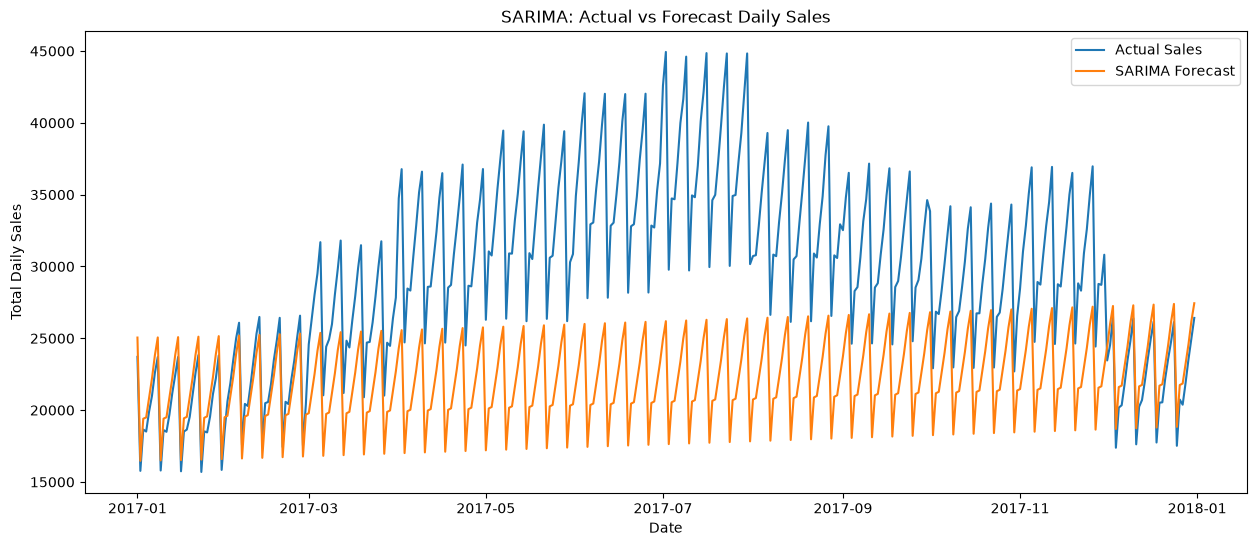

In [77]:
plt.figure(figsize=(15, 6))

plt.plot(sarima_test.index,
         sarima_test.values,
         label="Actual Sales")

plt.plot(sarima_test.index,
         sarima_forecast.values,
         label="SARIMA Forecast")

plt.title("SARIMA: Actual vs Forecast Daily Sales")
plt.xlabel("Date")
plt.ylabel("Total Daily Sales")
plt.legend()

plt.savefig("../visualizations/sarima_actual_vs_forecast.png",
            dpi=300, bbox_inches="tight")
plt.show()

### SARIMA Evaluation Conclusion

The SARIMA model achieved an MAE of 7,593.7690, an RMSE of 8,979.6414, and a MAPE of 23.6154% on the 2017 aggregate daily sales test dataset.

The model captures temporal and weekly seasonal patterns in aggregate sales.

Its performance will be considered alongside other forecasting approaches after evaluating them at a consistent aggregation level.

## 14. Prophet Forecasting

Prophet is a time-series forecasting model developed by Meta that captures trend, seasonality, and holiday effects.

In this project, Prophet is used to forecast aggregate daily sales across all stores and items.

The model is trained using historical daily sales from 2013 to 2016 and evaluated on the unseen 2017 dataset.

Prophet forecasting performance is evaluated using MAE, RMSE, and MAPE.

In [78]:
from prophet import Prophet

In [79]:
prophet_data = daily_sales.reset_index().rename(
    columns={"date": "ds", "sales": "y"}
)

In [80]:
prophet_train = prophet_data[
    prophet_data["ds"] < "2017-01-01"
].copy()

prophet_test = prophet_data[
    prophet_data["ds"] >= "2017-01-01"
].copy()

In [81]:
prophet_train.shape, prophet_test.shape

((1461, 2), (365, 2))

In [82]:
prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

In [83]:
prophet_model.fit(prophet_train)

23:42:31 - cmdstanpy - INFO - Chain [1] start processing
23:42:32 - cmdstanpy - INFO - Chain [1] done processing


In [84]:
future = prophet_model.make_future_dataframe(
    periods=len(prophet_test),
    freq="D"
)

In [85]:
prophet_forecast = prophet_model.predict(future)

In [86]:
prophet_predictions = prophet_forecast[
    prophet_forecast["ds"] >= "2017-01-01"
]["yhat"]

In [87]:
prophet_predictions.shape

(365,)

In [88]:
prophet_mae = mean_absolute_error(
    prophet_test["y"], prophet_predictions
)

prophet_rmse = np.sqrt(
    mean_squared_error(prophet_test["y"], prophet_predictions)
)

nonzero_mask = prophet_test["y"] != 0

prophet_mape = np.mean(
    np.abs(
        (
            prophet_test["y"][nonzero_mask]
            - prophet_predictions[nonzero_mask]
        )
        / prophet_test["y"][nonzero_mask]
    )
) * 100

print("Prophet MAE:", prophet_mae)
print("Prophet RMSE:", prophet_rmse)
print("Prophet MAPE:", prophet_mape)

Prophet MAE: 1471.3011588877941
Prophet RMSE: 1760.563543341432
Prophet MAPE: 5.554930561022969


### Prophet – Actual vs Predicted Daily Sales

This visualization compares actual aggregate daily sales
with Prophet forecasts during the 2017 test period.

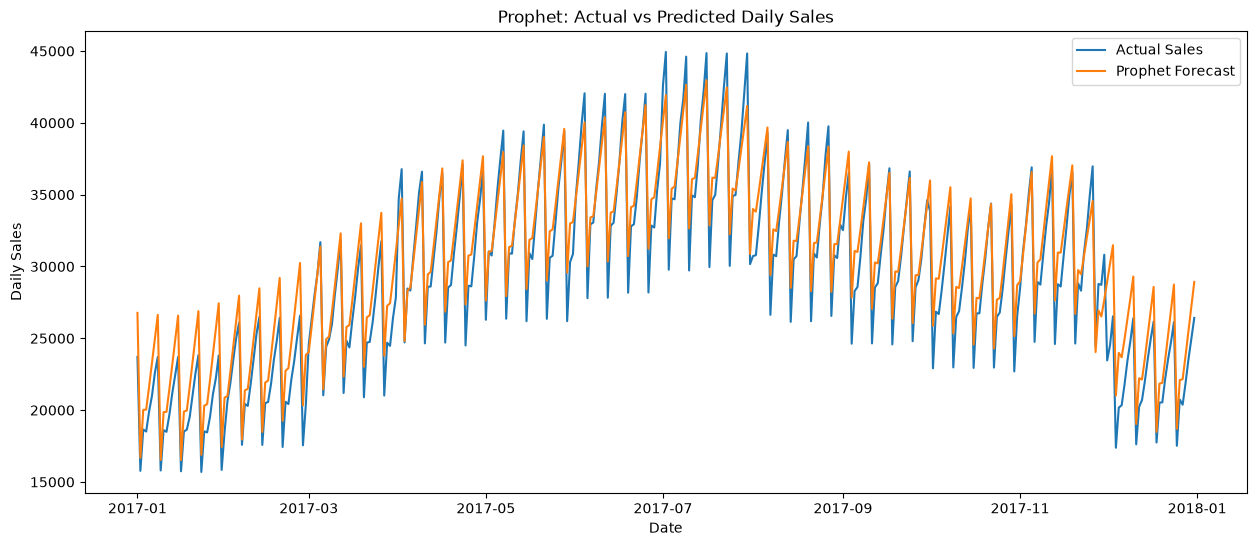

In [89]:
plt.figure(figsize=(15, 6))

plt.plot(prophet_test["ds"],
         prophet_test["y"],
         label="Actual Sales")

plt.plot(prophet_test["ds"],
         prophet_predictions,
         label="Prophet Forecast")

plt.title("Prophet: Actual vs Predicted Daily Sales")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()

plt.savefig("../visualizations/prophet_actual_vs_predicted.png",
            dpi=300, bbox_inches="tight")
plt.show()

## 15. Model Comparison

This section compares the performance of different forecasting models
using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE),
and Mean Absolute Percentage Error (MAPE).

The comparison helps evaluate forecasting accuracy and identify
the most suitable model for sales prediction.

### Model Performance Comparison

In [90]:
model_comparison = pd.DataFrame({
    "Model": ["Seasonal Naive", "Random Forest", "XGBoost", "SARIMA", "Prophet"],
    "MAE": [baseline_mae, rf_mae, xgb_mae, sarima_mae, prophet_mae],
    "RMSE": [baseline_rmse, rf_rmse, xgb_rmse, sarima_rmse, prophet_rmse],
    "MAPE": [baseline_mape, rf_mape, xgb_mape, sarima_mape, prophet_mape]
})

model_comparison

,Model,MAE,RMSE,MAPE
0,Seasonal Naive,8.841452,11.596704,17.935501
1,Random Forest,6.273002,8.156662,12.934868
2,XGBoost,6.101734,7.929730,12.587755
3,SARIMA,7593.769049,8979.641387,23.615391
4,Prophet,1471.301159,1760.563543,5.554931


### MAE Comparison

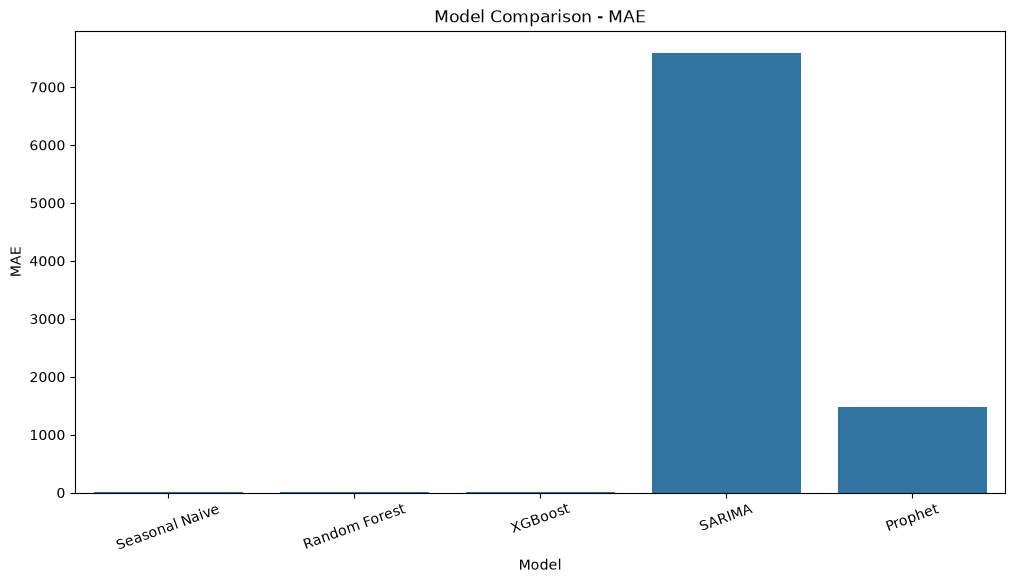

In [91]:
plt.figure(figsize=(12, 6))

sns.barplot(data=model_comparison, x="Model", y="MAE")

plt.title("Model Comparison - MAE")
plt.xlabel("Model")
plt.ylabel("MAE")
plt.xticks(rotation=20)

plt.savefig("../visualizations/model_comparison_mae.png",
            dpi=300, bbox_inches="tight")
plt.show()

### RMSE Comparison

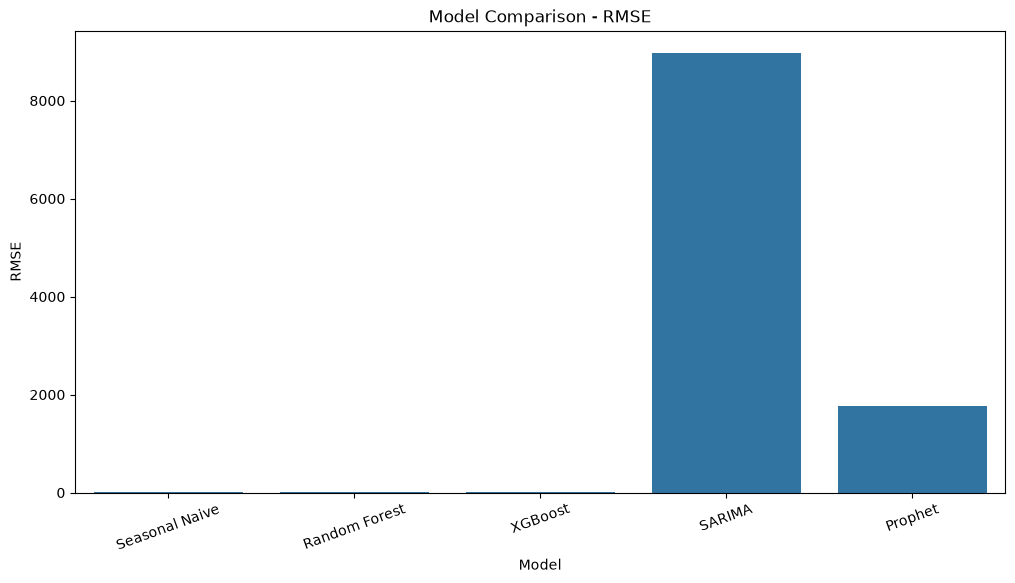

In [92]:
plt.figure(figsize=(12, 6))

sns.barplot(data=model_comparison, x="Model", y="RMSE")

plt.title("Model Comparison - RMSE")
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.xticks(rotation=20)

plt.savefig("../visualizations/model_comparison_rmse.png",
            dpi=300, bbox_inches="tight")
plt.show()

### MAPE Comparison

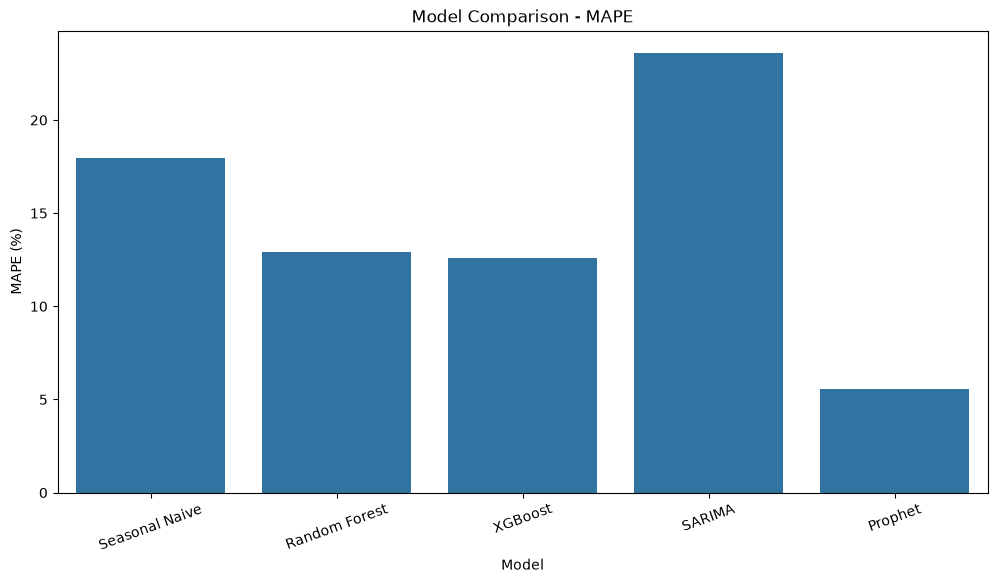

In [93]:
plt.figure(figsize=(12, 6))

sns.barplot(data=model_comparison, x="Model", y="MAPE")

plt.title("Model Comparison - MAPE")
plt.xlabel("Model")
plt.ylabel("MAPE (%)")
plt.xticks(rotation=20)

plt.savefig("../visualizations/model_comparison_mape.png",
            dpi=300, bbox_inches="tight")
plt.show()

### Model Comparison Conclusion

The forecasting models were evaluated using MAE, RMSE, and MAPE.
These metrics provide insights into prediction accuracy and model performance.

Prophet achieved the lowest MAE, RMSE, and MAPE among the aggregate daily forecasting models, outperforming SARIMA.

Random Forest and XGBoost demonstrated good performance for store-item sales prediction, with XGBoost outperforming Random Forest.

The final model selection will consider forecasting accuracy, prediction requirements, and the intended application.

### Aggregating Random Forest Predictions by Date

Random Forest generates predictions for individual store-item combinations.
These predictions are aggregated by date to obtain total daily sales
and enable comparison with aggregate daily forecasting models.

In [94]:
rf_test_results = test[["date"]].copy()

rf_test_results["actual_sales"] = y_test.values
rf_test_results["predicted_sales"] = y_pred_rf

rf_daily_comparison = rf_test_results.groupby("date").agg(
    actual_sales=("actual_sales", "sum"),
    predicted_sales=("predicted_sales", "sum")
)

rf_daily_comparison.head()

,actual_sales,predicted_sales
date,,
2017-01-01,23709,25108.707612
2017-01-02,15772,17457.750389
2017-01-03,18650,20356.209216
2017-01-04,18510,19975.884107
2017-01-05,19895,21235.213236


### Aggregating XGBoost Predictions by Date

XGBoost generates predictions for individual store-item combinations.
These predictions are aggregated by date to obtain total daily sales
and enable comparison with aggregate daily forecasting models.

In [95]:
xgb_test_results = test[["date"]].copy()

xgb_test_results["actual_sales"] = y_test.values
xgb_test_results["predicted_sales"] = y_pred_xgb

xgb_daily_comparison = xgb_test_results.groupby("date").agg(
    actual_sales=("actual_sales", "sum"),
    predicted_sales=("predicted_sales", "sum")
)

xgb_daily_comparison.head()

,actual_sales,predicted_sales
date,,
2017-01-01,23709,24671.285156
2017-01-02,15772,16783.210938
2017-01-03,18650,19475.146484
2017-01-04,18510,19448.525391
2017-01-05,19895,20561.480469


### Daily Aggregate Model Evaluation

Random Forest and XGBoost predictions are aggregated by date
to compare their forecasting performance with SARIMA and Prophet
on the same daily sales scale.

In [96]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Random Forest daily metrics
rf_actual = rf_daily_comparison["actual_sales"]
rf_predicted = rf_daily_comparison["predicted_sales"]

rf_daily_mae = mean_absolute_error(rf_actual, rf_predicted)
rf_daily_rmse = np.sqrt(mean_squared_error(rf_actual, rf_predicted))
rf_daily_mape = np.mean(np.abs((rf_actual - rf_predicted) / rf_actual)) * 100

# XGBoost daily metrics
xgb_actual = xgb_daily_comparison["actual_sales"]
xgb_predicted = xgb_daily_comparison["predicted_sales"]

xgb_daily_mae = mean_absolute_error(xgb_actual, xgb_predicted)
xgb_daily_rmse = np.sqrt(mean_squared_error(xgb_actual, xgb_predicted))
xgb_daily_mape = np.mean(np.abs((xgb_actual - xgb_predicted) / xgb_actual)) * 100

# Display results
print("Random Forest Daily MAE:", rf_daily_mae)
print("Random Forest Daily RMSE:", rf_daily_rmse)
print("Random Forest Daily MAPE:", rf_daily_mape)

print("\nXGBoost Daily MAE:", xgb_daily_mae)
print("XGBoost Daily RMSE:", xgb_daily_rmse)
print("XGBoost Daily MAPE:", xgb_daily_mape)

Random Forest Daily MAE: 376.396369828171
Random Forest Daily RMSE: 586.8990103350606
Random Forest Daily MAPE: 1.3832190600010714

XGBoost Daily MAE: 208.45562744140625
XGBoost Daily RMSE: 280.62305121817775
XGBoost Daily MAPE: 0.7582812339939168


In [97]:

# Save XGBoost daily comparison data

xgb_daily_comparison.to_csv(
    "../data/processed/xgboost_daily_comparison.csv",
    index=False
)

print("XGBoost comparison data saved successfully!")
print(xgb_daily_comparison.head())


XGBoost comparison data saved successfully!
            actual_sales  predicted_sales
date                                     
2017-01-01         23709     24671.285156
2017-01-02         15772     16783.210938
2017-01-03         18650     19475.146484
2017-01-04         18510     19448.525391
2017-01-05         19895     20561.480469


### Aggregating Seasonal Naive Predictions by Date

Seasonal Naive predictions are generated for individual store-item combinations.
These predictions are aggregated by date to calculate total daily sales
and enable fair comparison with daily forecasting models.

In [98]:
baseline_test_results = test[["date"]].copy()

baseline_test_results["actual_sales"] = y_test.values
baseline_test_results["predicted_sales"] = y_pred_baseline.values

baseline_daily_comparison = baseline_test_results.groupby("date").agg(
    actual_sales=("actual_sales", "sum"),
    predicted_sales=("predicted_sales", "sum")
)

baseline_daily_comparison.head()

,actual_sales,predicted_sales
date,,
2017-01-01,23709,25195.0
2017-01-02,15772,16831.0
2017-01-03,18650,19341.0
2017-01-04,18510,19560.0
2017-01-05,19895,21111.0


In [99]:
baseline_actual = baseline_daily_comparison["actual_sales"]
baseline_predicted = baseline_daily_comparison["predicted_sales"]

baseline_daily_mae = mean_absolute_error(
    baseline_actual, baseline_predicted
)

baseline_daily_rmse = np.sqrt(mean_squared_error(
    baseline_actual, baseline_predicted
))

baseline_daily_mape = np.mean(
    np.abs((baseline_actual - baseline_predicted) / baseline_actual)
) * 100

print("Seasonal Naive Daily MAE:", baseline_daily_mae)
print("Seasonal Naive Daily RMSE:", baseline_daily_rmse)
print("Seasonal Naive Daily MAPE:", baseline_daily_mape)

Seasonal Naive Daily MAE: 902.5616438356165
Seasonal Naive Daily RMSE: 1868.4138207258723
Seasonal Naive Daily MAPE: 3.245869008647701


## 16. Daily Aggregate Model Comparison

This section compares all forecasting models using daily aggregate sales.
All models are evaluated on the same 365 days of actual sales in 2017
using MAE, RMSE, and MAPE.

In [100]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Actual daily sales for 2017
daily_actual = daily_sales.loc["2017-01-01":"2017-12-31", "sales"]

# Collect daily predictions from all models
daily_predictions = {
    "Seasonal Naive": baseline_daily_comparison["predicted_sales"],
    "Random Forest": rf_daily_comparison["predicted_sales"],
    "XGBoost": xgb_daily_comparison["predicted_sales"],
    "SARIMA": sarima_forecast,
    "Prophet": prophet_predictions
}

# Calculate all three metrics
daily_model_results = []

for model_name, predictions in daily_predictions.items():
    predictions = np.asarray(predictions)

    mae = mean_absolute_error(daily_actual, predictions)
    rmse = np.sqrt(mean_squared_error(daily_actual, predictions))
    mape = np.mean(np.abs((daily_actual.values - predictions)
                           / daily_actual.values)) * 100

    daily_model_results.append({
        "Model": model_name,
        "Daily MAE": mae,
        "Daily RMSE": rmse,
        "Daily MAPE (%)": mape
    })

daily_model_comparison = pd.DataFrame(daily_model_results)

daily_model_comparison

,Model,Daily MAE,Daily RMSE,Daily MAPE (%)
0,Seasonal Naive,902.561644,1868.413821,3.245869
1,Random Forest,376.396370,586.899010,1.383219
2,XGBoost,208.455627,280.623051,0.758281
3,SARIMA,7593.769049,8979.641387,23.615391
4,Prophet,1471.301159,1760.563543,5.554931


### Daily Aggregate Model Comparison Visualization

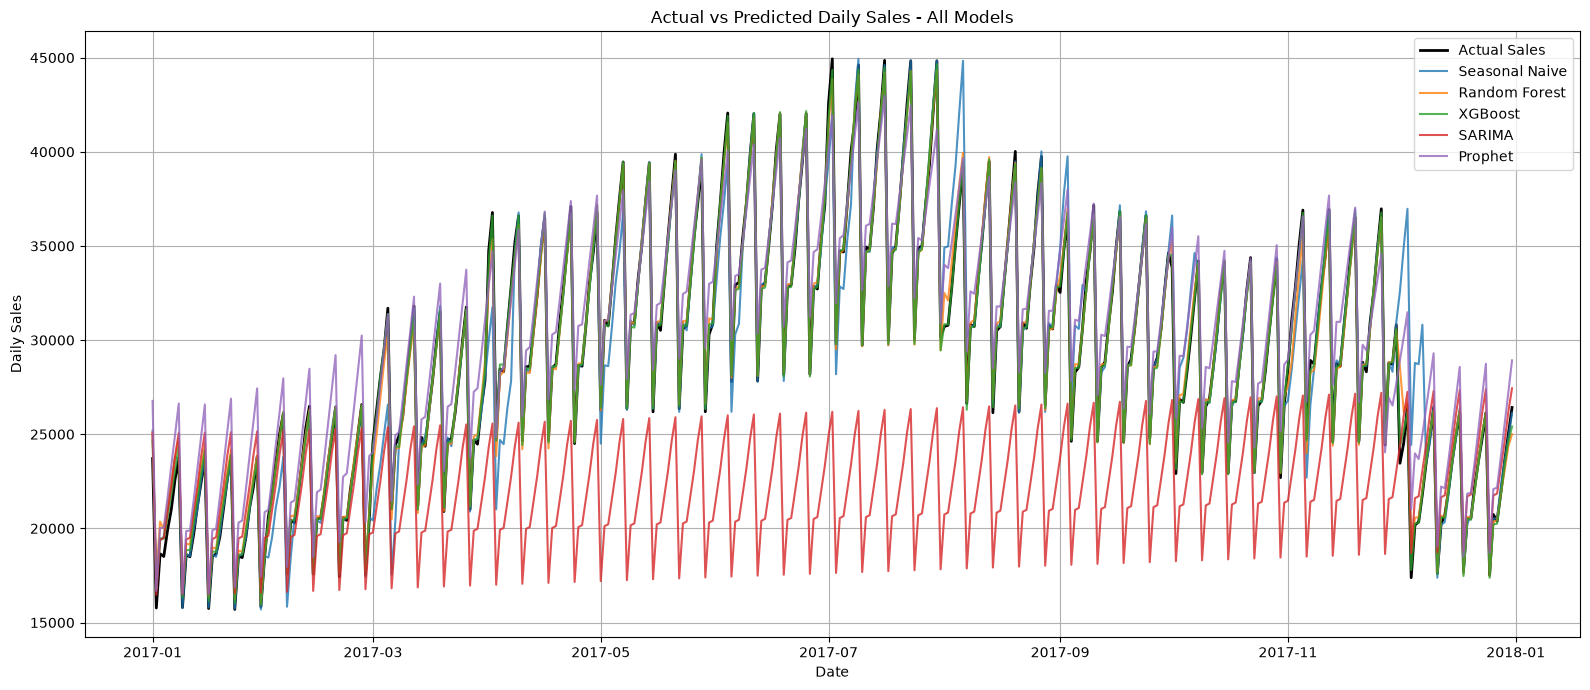

In [101]:


import matplotlib.pyplot as plt

plt.figure(figsize=(16, 7))

# Actual daily sales
plt.plot(
    daily_actual.index,
    daily_actual.values,
    label="Actual Sales",
    color="black",
    linewidth=2
)

# Model predictions
for model_name, predictions in daily_predictions.items():
    plt.plot(
        daily_actual.index,
        np.asarray(predictions),
        label=model_name,
        alpha=0.8
    )

plt.title("Actual vs Predicted Daily Sales - All Models")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()

# Save visualization
plt.savefig(
    "../visualizations/all_models_daily_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


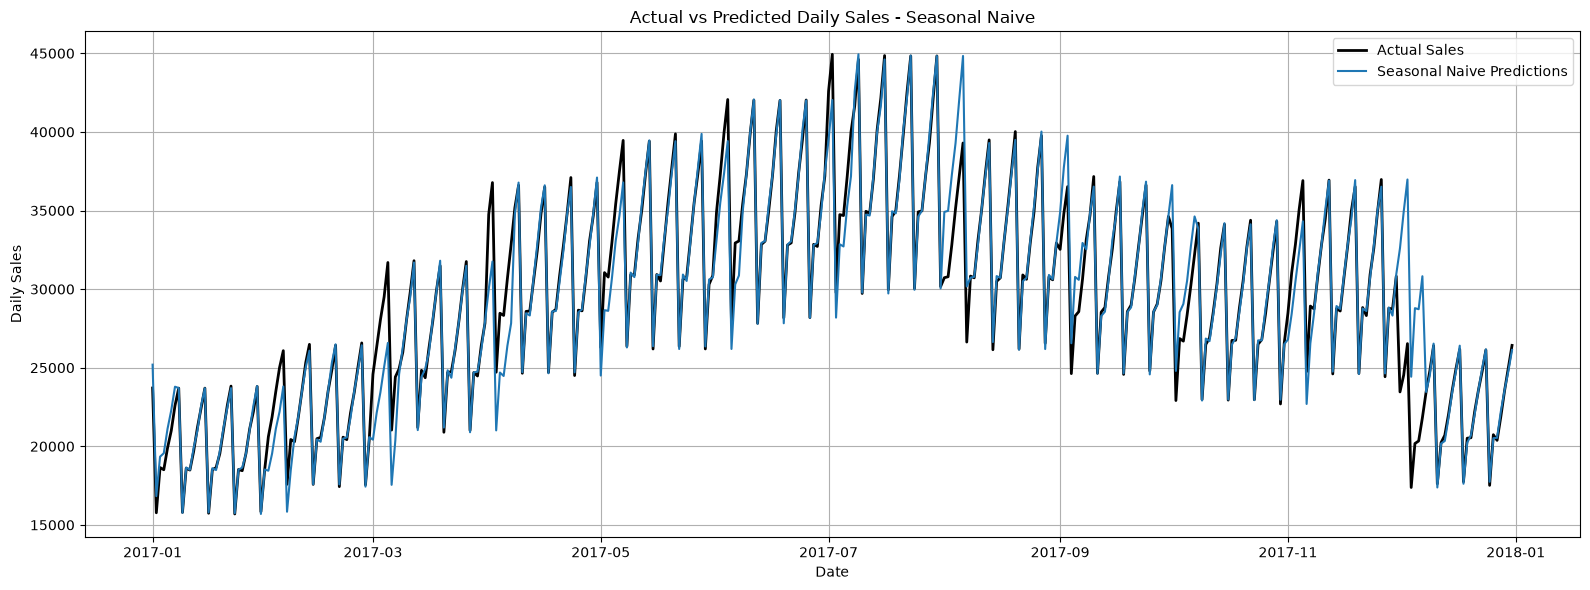

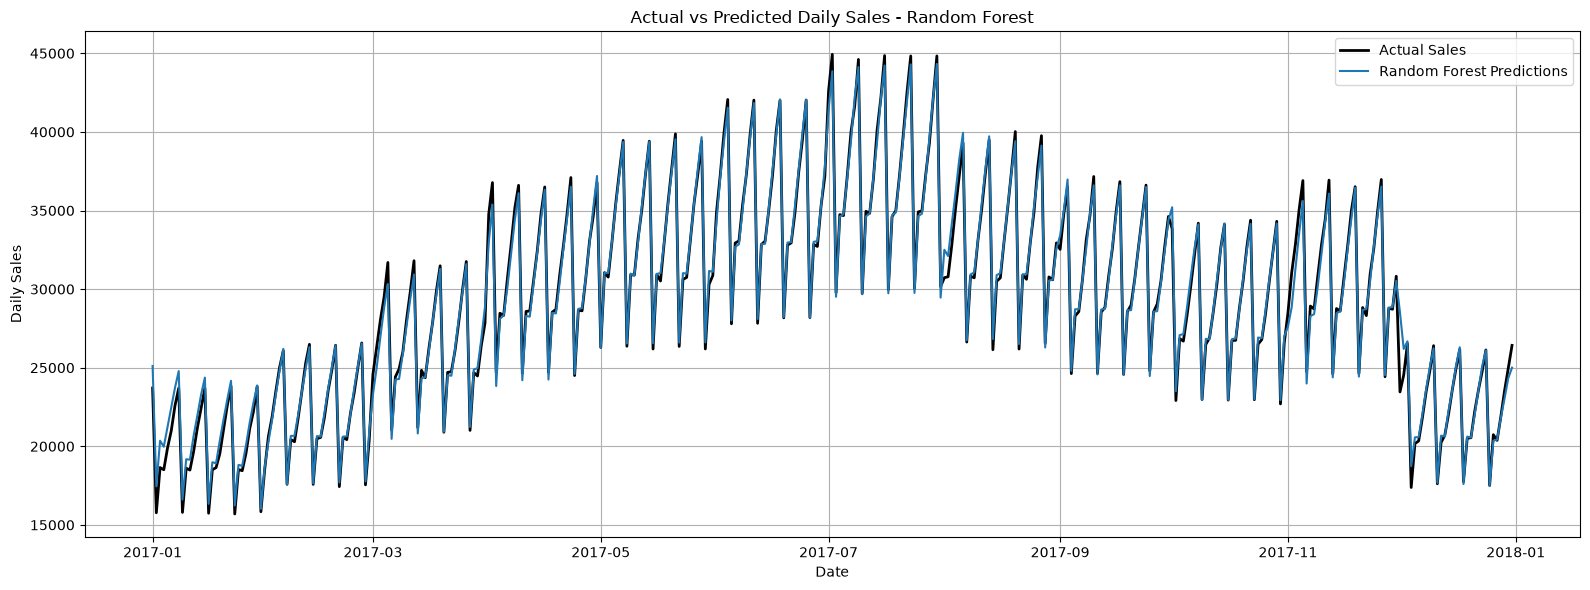

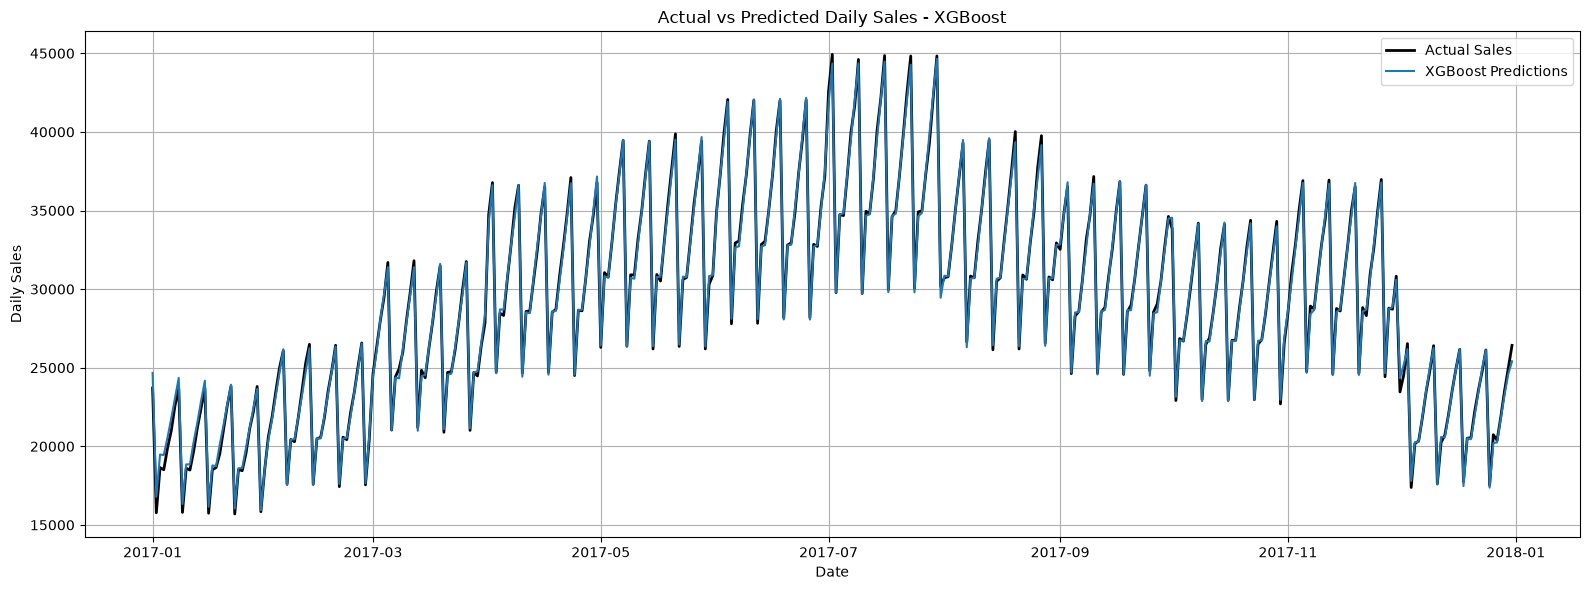

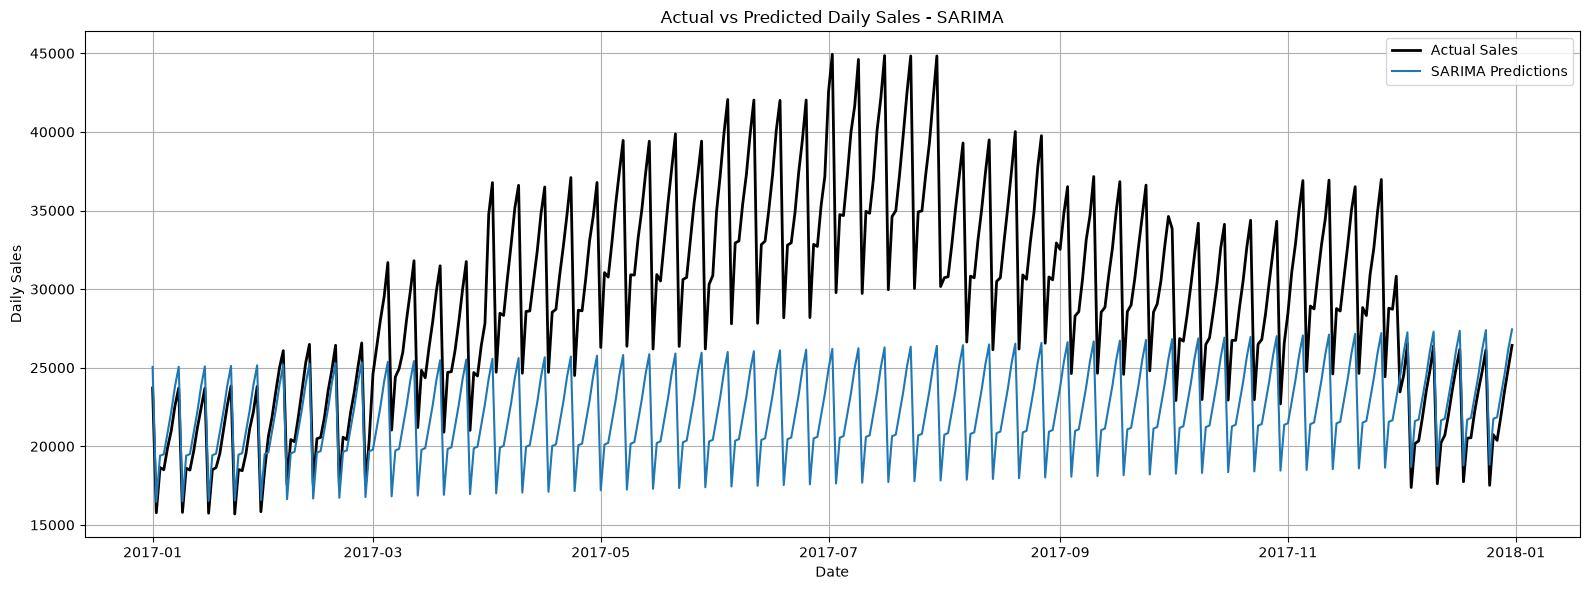

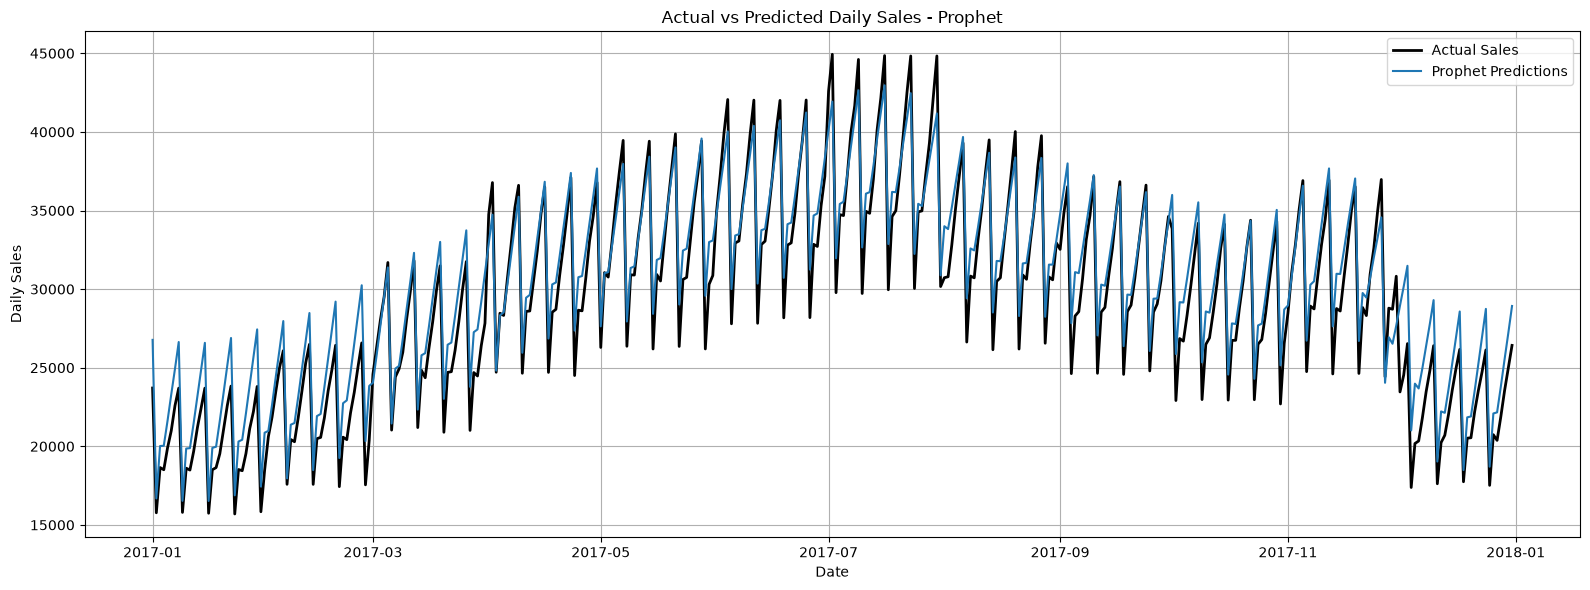

In [102]:

import matplotlib.pyplot as plt

for model_name, predictions in daily_predictions.items():

    plt.figure(figsize=(16, 6))

    plt.plot(
        daily_actual.index,
        daily_actual.values,
        label="Actual Sales",
        color="black",
        linewidth=2
    )

    plt.plot(
        daily_actual.index,
        np.asarray(predictions),
        label=f"{model_name} Predictions",
        linewidth=1.5
    )

    plt.title(f"Actual vs Predicted Daily Sales - {model_name}")
    plt.xlabel("Date")
    plt.ylabel("Daily Sales")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    filename = model_name.lower().replace(" ", "_")

    plt.savefig(
        f"../visualizations/{filename}_daily_comparison.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


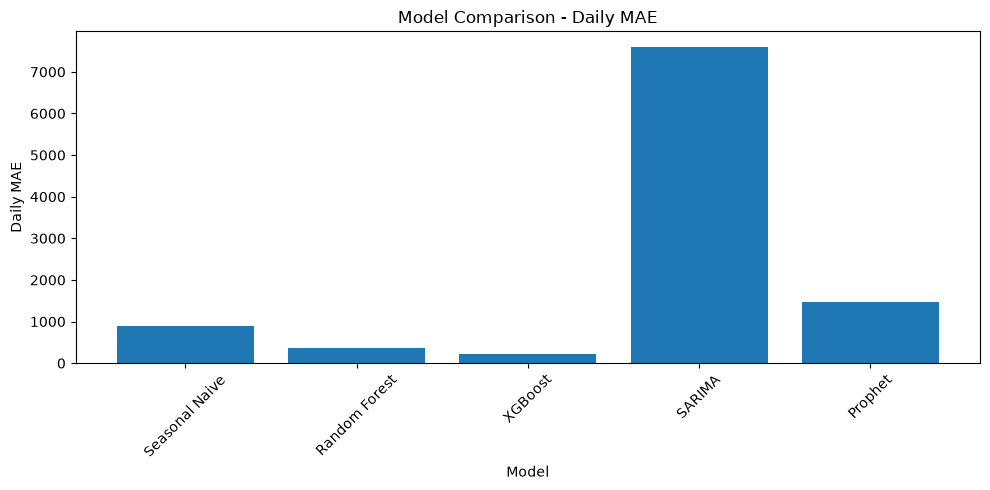

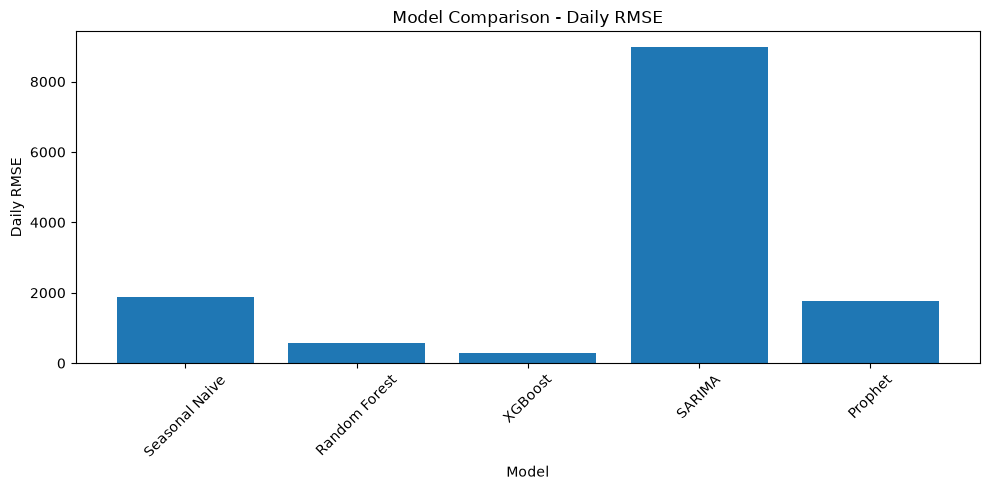

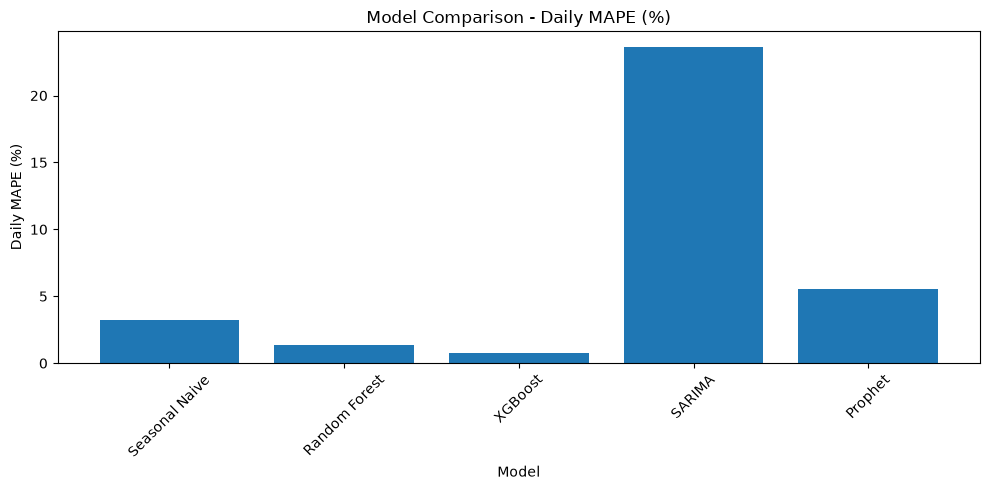

In [103]:
import matplotlib.pyplot as plt

metrics = ["Daily MAE", "Daily RMSE", "Daily MAPE (%)"]

for metric in metrics:
    plt.figure(figsize=(10, 5))

    plt.bar(
        daily_model_comparison["Model"],
        daily_model_comparison[metric]
    )

    plt.title(f"Model Comparison - {metric}")
    plt.xlabel("Model")
    plt.ylabel(metric)
    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.savefig(f"../visualizations/daily_model_comparison_{metric.replace(' ', '_').replace('(', '').replace(')', '').replace('%', 'percent').lower()}.png")

    plt.show()

In [104]:
daily_model_comparison.to_csv(
    "../reports/daily_model_comparison.csv",
    index=False
)

## 17. Final Model Selection

Based on the daily aggregate evaluation, XGBoost achieved the lowest
forecasting errors among all five models.

The model achieved:
- Daily MAE: 208.46
- Daily RMSE: 280.62
- Daily MAPE: 0.76%

Therefore, XGBoost is selected as the final forecasting model
for the Demand Forecasting and Sales Prediction project.

In [105]:
best_model = daily_model_comparison.loc[
    daily_model_comparison["Daily MAE"].idxmin()
]

print("Best Model:", best_model["Model"])
print("Daily MAE:", best_model["Daily MAE"])
print("Daily RMSE:", best_model["Daily RMSE"])
print("Daily MAPE:", best_model["Daily MAPE (%)"])

Best Model: XGBoost
Daily MAE: 208.45562744140625
Daily RMSE: 280.62305121817775
Daily MAPE: 0.7582812339939168


## 18. Model Saving

The trained XGBoost model is saved using Joblib.
This allows the model to be loaded later for predictions
without repeating the training process.

In [106]:
import joblib

joblib.dump(xgb_model, "../models/xgboost_sales_model.pkl")

print("XGBoost model saved successfully.")

XGBoost model saved successfully.


In [107]:
loaded_model = joblib.load("../models/xgboost_sales_model.pkl")

sample_predictions = loaded_model.predict(X_test.iloc[:10])

print("Sample Predictions:", sample_predictions)

Sample Predictions: [19.227491 13.567878 15.795521 14.972742 16.156118 16.759556 17.322067
 19.2977   13.226199 15.361037]


# 19. Model Prediction Verification

The saved XGBoost model is loaded and tested on sample test records.
This verifies that the saved model can generate predictions
without retraining.

In [108]:
import joblib

# Load the saved XGBoost model
loaded_model = joblib.load("../models/xgboost_sales_model.pkl")

# Generate predictions for the first 10 test records
sample_predictions = loaded_model.predict(X_test.iloc[:10])

print("Sample Predictions:", sample_predictions)

Sample Predictions: [19.227491 13.567878 15.795521 14.972742 16.156118 16.759556 17.322067
 19.2977   13.226199 15.361037]


## Recursive Forecasting

Recursive forecasting predicts future sales one day at a time.
The predictions from previous days are used to calculate lag
features for the next day's forecast.

In [109]:
import sys
from pathlib import Path

project_root = Path.cwd().parent
sys.path.append(str(project_root))

from src.forecasting import recursive_forecast

print("Recursive forecasting function imported successfully.")

Recursive forecasting function imported successfully.


In [110]:
recursive_predictions = recursive_forecast(
    model=xgb_model,
    history=df,
    forecast_days=7
)

print("Forecast Shape:", recursive_predictions.shape)
print(recursive_predictions.head())

Forecast Shape: (3500, 4)
        date  store  item  predicted_sales
0 2018-01-01      1     1        13.846163
1 2018-01-01      1     2        35.769852
2 2018-01-01      1     3        21.085001
3 2018-01-01      1     4        12.491128
4 2018-01-01      1     5        11.457406


In [111]:
print("Forecast Start:", recursive_predictions["date"].min())
print("Forecast End:", recursive_predictions["date"].max())
print("Unique Forecast Dates:", recursive_predictions["date"].nunique())
print("Missing Values:", recursive_predictions.isnull().sum().sum())

Forecast Start: 2018-01-01 00:00:00
Forecast End: 2018-01-07 00:00:00
Unique Forecast Dates: 7
Missing Values: 0


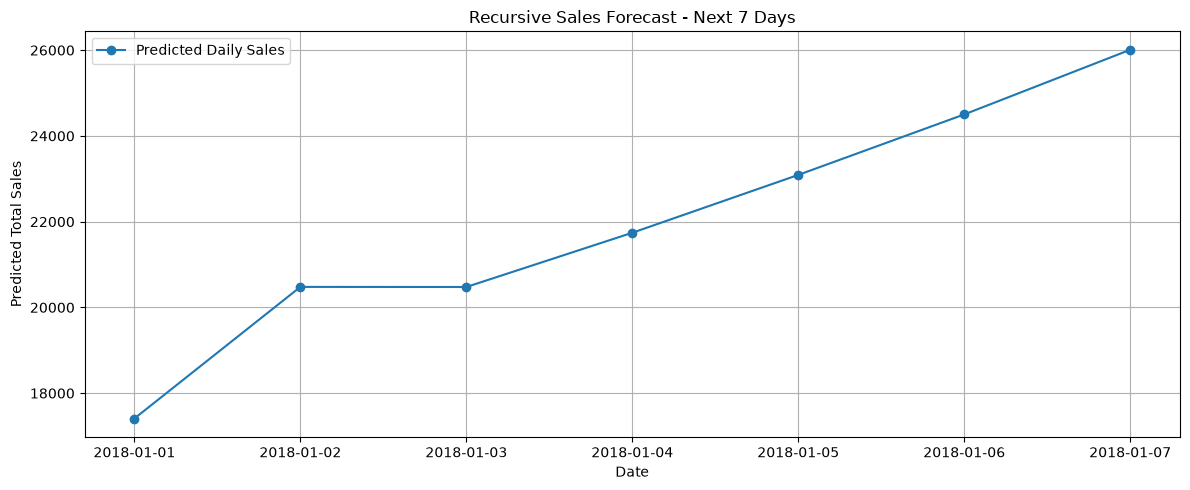

In [112]:
import matplotlib.pyplot as plt

recursive_daily_sales = (
    recursive_predictions.groupby("date")["predicted_sales"]
    .sum()
)

plt.figure(figsize=(12, 5))

plt.plot(
    recursive_daily_sales.index,
    recursive_daily_sales.values,
    marker="o",
    label="Predicted Daily Sales"
)

plt.title("Recursive Sales Forecast - Next 7 Days")
plt.xlabel("Date")
plt.ylabel("Predicted Total Sales")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "../visualizations/recursive_sales_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [113]:
recursive_predictions.to_csv(
    "../reports/recursive_sales_forecast.csv",
    index=False
)

print("Recursive forecast saved successfully.")

Recursive forecast saved successfully.


In [114]:
print("Minimum Predicted Sales:", recursive_predictions["predicted_sales"].min())
print("Negative Predictions:", (recursive_predictions["predicted_sales"] < 0).sum())

Minimum Predicted Sales: 8.927238
Negative Predictions: 0


In [115]:
# Select historical data for recursive evaluation
evaluation_history = df[df["date"] < "2017-01-01"].copy()

evaluation_actual = df[
    (df["date"] >= "2017-01-01") &
    (df["date"] <= "2017-01-31")
].copy()

print("History End Date:", evaluation_history["date"].max())
print("Evaluation Start:", evaluation_actual["date"].min())
print("Evaluation End:", evaluation_actual["date"].max())
print("Actual Records:", evaluation_actual.shape[0])

History End Date: 2016-12-31 00:00:00
Evaluation Start: 2017-01-01 00:00:00
Evaluation End: 2017-01-31 00:00:00
Actual Records: 15500


In [116]:
recursive_january = recursive_forecast(
    model=xgb_model,
    history=evaluation_history,
    forecast_days=31
)

print("Recursive Forecast Shape:", recursive_january.shape)
print(recursive_january.head())

Recursive Forecast Shape: (15500, 4)
        date  store  item  predicted_sales
0 2017-01-01      1     1        19.227491
1 2017-01-01      1     2        48.618565
2 2017-01-01      1     3        30.946053
3 2017-01-01      1     4        20.437166
4 2017-01-01      1     5        15.951232


In [117]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

recursive_actual = evaluation_actual["sales"].values
recursive_predicted = recursive_january["predicted_sales"].values

recursive_mae = mean_absolute_error(
    recursive_actual,
    recursive_predicted
)

recursive_rmse = np.sqrt(
    mean_squared_error(recursive_actual, recursive_predicted)
)

recursive_mape = (
    np.abs((recursive_actual - recursive_predicted) / recursive_actual).mean()
    * 100
)

print("Recursive MAE:", recursive_mae)
print("Recursive RMSE:", recursive_rmse)
print("Recursive MAPE:", recursive_mape)

Recursive MAE: 22.3469295501709
Recursive RMSE: 27.955628250477687
Recursive MAPE: 79.48532697633017


In [118]:
# Get original XGBoost predictions for January 2017
january_mask = test["date"].between("2017-01-01", "2017-01-31")

january_X = test.loc[january_mask, features]
january_y = test.loc[january_mask, "sales"]

january_original_predictions = xgb_model.predict(january_X)

original_january_mae = mean_absolute_error(
    january_y, january_original_predictions
)

original_january_rmse = np.sqrt(
    mean_squared_error(january_y, january_original_predictions)
)

original_january_mape = (
    np.abs(
        (january_y.values - january_original_predictions)
        / january_y.values
    ).mean() * 100
)

print("Original XGBoost January MAE:", original_january_mae)
print("Original XGBoost January RMSE:", original_january_rmse)
print("Original XGBoost January MAPE:", original_january_mape)

Original XGBoost January MAE: 5.019939422607422
Original XGBoost January RMSE: 6.47811668531636
Original XGBoost January MAPE: 15.635282078995186


In [119]:
january_comparison = pd.DataFrame({
    "Model": ["Original XGBoost", "Recursive XGBoost"],
    "MAE": [original_january_mae, recursive_mae],
    "RMSE": [original_january_rmse, recursive_rmse],
    "MAPE (%)": [original_january_mape, recursive_mape]
})

january_comparison

,Model,MAE,RMSE,MAPE (%)
0,Original XGBoost,5.019939,6.478117,15.635282
1,Recursive XGBoost,22.346930,27.955628,79.485327


In [120]:
january_comparison.style.hide(axis="index")

Model,MAE,RMSE,MAPE (%)
Original XGBoost,5.019939,6.478117,15.635282
Recursive XGBoost,22.346930,27.955628,79.485327


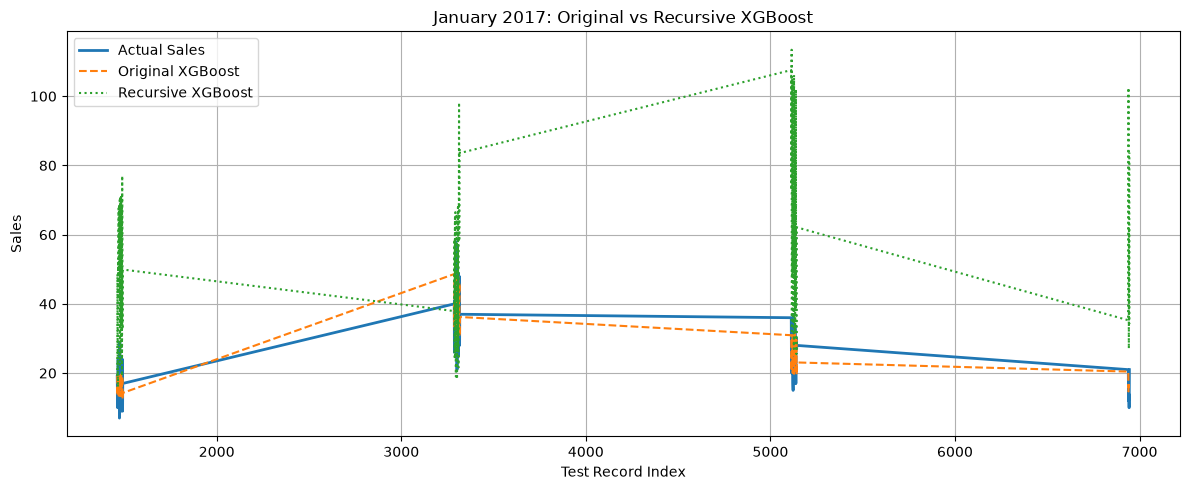

In [121]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    january_y.index[:100],
    january_y.values[:100],
    label="Actual Sales",
    linewidth=2
)

plt.plot(
    january_y.index[:100],
    january_original_predictions[:100],
    label="Original XGBoost",
    linestyle="--"
)

plt.plot(
    january_y.index[:100],
    recursive_january["predicted_sales"].values[:100],
    label="Recursive XGBoost",
    linestyle=":"
)

plt.title("January 2017: Original vs Recursive XGBoost")
plt.xlabel("Test Record Index")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "../visualizations/january_recursive_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

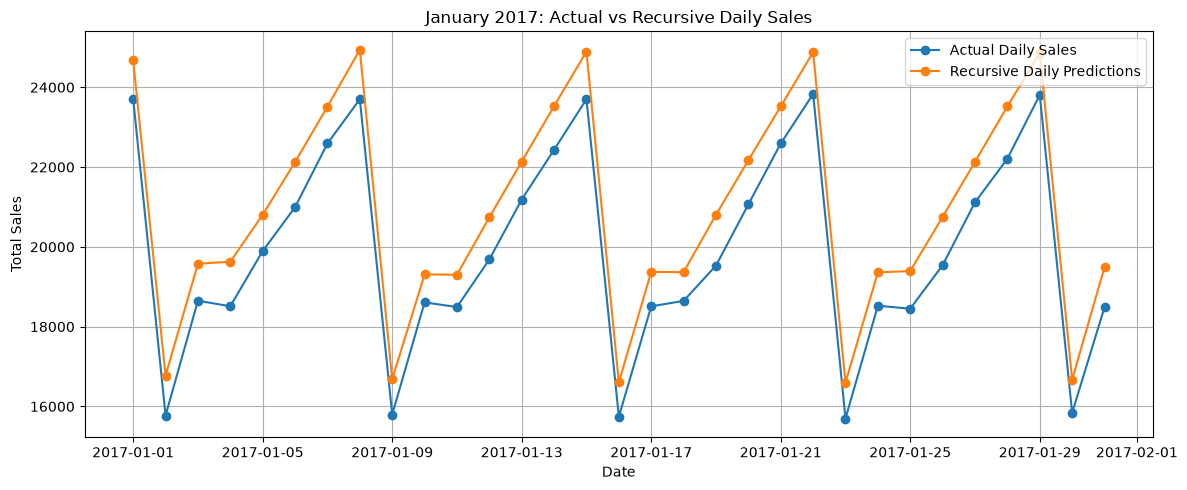

In [122]:
# Aggregate actual and recursive predictions by date
actual_daily = evaluation_actual.groupby("date")["sales"].sum()

recursive_daily = recursive_january.groupby("date")["predicted_sales"].sum()

plt.figure(figsize=(12, 5))

plt.plot(
    actual_daily.index,
    actual_daily.values,
    label="Actual Daily Sales",
    marker="o"
)

plt.plot(
    recursive_daily.index,
    recursive_daily.values,
    label="Recursive Daily Predictions",
    marker="o"
)

plt.title("January 2017: Actual vs Recursive Daily Sales")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "../visualizations/january_recursive_daily_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [123]:
future_daily_sales = (
    recursive_predictions.groupby("date")["predicted_sales"]
    .sum()
)

print("Total Forecast Sales:", future_daily_sales.sum())
print("Average Daily Forecast:", future_daily_sales.mean())

print("Highest Sales Day:", future_daily_sales.idxmax())
print("Highest Predicted Sales:", future_daily_sales.max())

print("Lowest Sales Day:", future_daily_sales.idxmin())
print("Lowest Predicted Sales:", future_daily_sales.min())

Total Forecast Sales: 153704.89
Average Daily Forecast: 21957.842
Highest Sales Day: 2018-01-07 00:00:00
Highest Predicted Sales: 26009.135
Lowest Sales Day: 2018-01-01 00:00:00
Lowest Predicted Sales: 17408.701
